#  Credit Risk & Loan Default Prediction — Predicting Next-Month Payment Default of Credit Card Customers with Tree-Ensemble Models

**Name:** Siddhant Baliyan  
**Project title:** Credit Risk & Loan Default Prediction — Predicting Next-Month Payment Default of Credit Card Customers with Tree-Ensemble Models  


**Workflow rules**
1. Split first (stratified 80/20, `random_state=42`). The test split is used **once**, in section 8.2, after the model and threshold are fixed. A guard in the code enforces this.
2. All learned preprocessing (quantile bins, scaling, encoding, resampling) lives inside pipelines and is re-fitted in every CV fold.
3. Models are selected on cross-validated **average precision (AP)** on the training split.
4. Every experiment is logged, including ones that did not help.

**How to run:** keep `credit_default_24k.csv` in `data/` (downloaded automatically if missing) and use *Restart kernel and Run All*. Heavy steps are cached in a `cache/` folder, so a re-run is quick; delete `cache/` to recompute everything from scratch. A full from-scratch run takes roughly 45–75 minutes on one CPU core.

In [ ]:
import warnings, time, json, pickle, urllib.request, platform, random
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
for d_ in ['figures', 'outputs', 'cache']: Path(d_).mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 50)
versions = {'Python': platform.python_version()}
for p in ['pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn', 'scikit-learn', 'xgboost', 'lightgbm', 'imbalanced-learn']:
    try: versions[p] = version(p)
    except PackageNotFoundError: versions[p] = 'Not installed'
display(pd.DataFrame(versions.items(), columns=['Package', 'Version']))

DATA_PATH = Path('data/credit_default_24k.csv')
DOWNLOAD_URL = 'https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/credit.csv'
TARGET = 'default'
USE_CACHE = True
RESULTS = {}

def cached(name, fn):
    """Run fn() once and store the (plain-data) result in cache/; reuse it on later runs."""
    p = Path('cache') / f'{name}.pkl'
    if USE_CACHE and p.exists():
        return pickle.load(open(p, 'rb'))
    out = fn(); pickle.dump(out, open(p, 'wb')); return out

def plain(d): return {k: (v.item() if isinstance(v, np.generic) else v) for k, v in d.items()}
TEST_TOUCHED = False
def use_test():
    global TEST_TOUCHED
    assert not TEST_TOUCHED, 'The test split has already been used once; it must not be reused.'
    TEST_TOUCHED = True
    return X_test, y_test

,Package,Version
0,Python,3.13.16
1,pandas,2.2.3
2,numpy,2.4.6
3,scipy,1.16.3
4,matplotlib,3.10.0
5,seaborn,0.13.2
6,scikit-learn,1.6.1
7,xgboost,3.4.1
8,lightgbm,4.6.0
9,imbalanced-learn,0.14.2


## 1. Problem Statement & Objective

**Problem (P1 — Credit Risk & Loan Default Prediction, BFSI).** Predict whether a credit card customer will default on the payment due next month, from their credit limit, demographics and six months of repayment status, bill amounts and payment amounts. Binary classification, one row per customer; the data describe card default, so "loan default" means failure to pay a card obligation.

**Business relevance.** A card issuer's credit-risk and collections teams can use a risk ranking to set limits, send early reminders or offer restructuring to the riskiest accounts. A missed defaulter becomes a credit loss; a false alarm costs customer goodwill and income. Because only about 22% of customers default, accuracy is misleading (always predicting "no default" is about 78% accurate), so the project selects models on **average precision** and judges the final decision rule with an explicit **cost assumption**.

**Explicit cost assumption (stated here, used in section 8).** A missed defaulter is assumed to cost **5 times** as much as a false alarm (cost ratio 5 : 1). The data contain no loss or contact-cost figures, so 5 is an assumption, not a measurement: a missed default can lose a large part of the outstanding balance, while a false alarm costs a reminder, possible limit friction and some goodwill. Section 8 shows how the chosen threshold and the results change for ratios from 2 to 10, so the conclusions do not rest on this single number.

## 2. Dataset Description

| Item | Details |
|---|---|
| Dataset | Default of Credit Card Clients (UCI Machine Learning Repository, dataset 350). Working copy: the 24,000-row `credit.csv` from the PyCaret dataset repository, which appears to be a subset of the full 30,000-row UCI file |
| Source | https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients — Yeh, I. (2009), doi:10.24432/C55S3H (CC BY 4.0). Working copy: https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/credit.csv |
| Size | 24,000 rows × 24 columns (23 inputs + target) |
| Target | `default`: 1 = defaulted on next month's payment (October 2005), 0 = did not (about 22% positives) |
| Inputs | `LIMIT_BAL` (credit limit, NT$); `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`; `PAY_1`–`PAY_6` (repayment status, September back to April 2005: −1 paid duly, 1+ months of delay; −2 and 0 are undefined in the source); `BILL_AMT1`–`BILL_AMT6` (monthly bills); `PAY_AMT1`–`PAY_AMT6` (monthly payments) |
| Population / period | Credit card customers of a bank in Taiwan, April–October 2005 |
| Limitations | One snapshot with no customer ID (no time-based or grouped split possible); undefined category codes; 24,000 of the 30,000 UCI rows; sensitive attributes (`SEX`, `AGE`, `MARRIAGE`) present |

The full field-by-field data dictionary was submitted with the Week-2 outline.

## 3. Data Preparation & Feature Engineering

### 3.1 Load, remove duplicates, split

Exact duplicates are removed **before** splitting so identical rows cannot sit on both sides of the split.

In [ ]:
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True); urllib.request.urlretrieve(DOWNLOAD_URL, DATA_PATH)
raw = pd.read_csv(DATA_PATH)
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]; pay_cols = [f'PAY_{i}' for i in range(1, 7)]; pay_amt_cols = [f'PAY_AMT{i}' for i in range(1, 7)]
dups = raw[raw.duplicated(keep=False)]
print('Raw shape:', raw.shape, '| rows in duplicate groups:', len(dups), '| extra copies:', int(raw.duplicated().sum()))
print('Duplicate-group rows with zero bills and payments in all six months:',
      int(((dups[bill_cols].abs().sum(axis=1) + dups[pay_amt_cols].sum(axis=1)) == 0).sum()))
data = raw.drop_duplicates().reset_index(drop=True)
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
X = data.drop(columns=TARGET); y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train = X_train.reset_index(drop=True); y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True); y_test = y_test.reset_index(drop=True)
print('Train:', X_train.shape, 'default rate', round(y_train.mean(), 4), '| Test:', X_test.shape, '(held out until section 8.2)')
RESULTS.update(n_raw=len(raw), n_dups=int(raw.duplicated().sum()), n_clean=len(data), n_train=len(X_train), n_test=len(X_test),
               train_rate=float(y_train.mean()), test_rate=float(y_test.mean()))

Raw shape: (24000, 24) | rows in duplicate groups: 48 | extra copies: 24
Duplicate-group rows with zero bills and payments in all six months: 42
Train: (19180, 23) default rate 0.2211 | Test: (4796, 23) (held out until section 8.2)


**Observation.** 24 exact duplicates were dropped (0.1%), leaving 23,976 rows; 42 of the 48 rows in duplicate groups have zero bills and payments in all six months, so many may be different customers with empty records. They were dropped anyway: with no customer ID the cases cannot be told apart, the loss is tiny, and it prevents the same row from appearing on both sides of the split. Split sizes are 19,180 train and 4,796 test rows (22.1% default in both). Skewness of the amount columns falls from up to 23.5 (raw) to at most 2.1 in absolute value after the signed log.

### 3.2 Cleaning decisions

| Issue | Decision |
|---|---|
| Exact duplicates | Dropped before the split |
| `EDUCATION` 0/5/6 and `MARRIAGE` 0 (undefined codes) | Grouped with "others" (4 and 3) using Week-5 training-split evidence (codes 4 and 5 default at 3–6%, far below codes 1–3) |
| `PAY_x` −2 and 0 | Kept as ordered numbers; delay features use `max(PAY_x, 0)` so −2, −1 and 0 all mean "no delay" |
| Negative bills | Kept as credit balances |
| Skewed amounts | Signed log `sign(x)·log(1+|x|)` then scaling for Logistic Regression only; tree models use raw amounts |
| Outliers | Not removed (real customers; trees are insensitive; log tames them for the linear model) |
| Encoding / scaling | One-hot for categorical codes and bins, `StandardScaler` for numerics, fitted inside each CV fold |

,LIMIT_BAL,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
raw,1.00,2.66,2.73,2.73,2.82,2.89,2.86,12.27,23.53,16.24,12.11,10.80,11.05
signed_log,-0.52,-2.09,-1.94,-1.85,-1.78,-1.68,-1.56,-1.31,-1.25,-1.07,-0.96,-0.94,-0.85


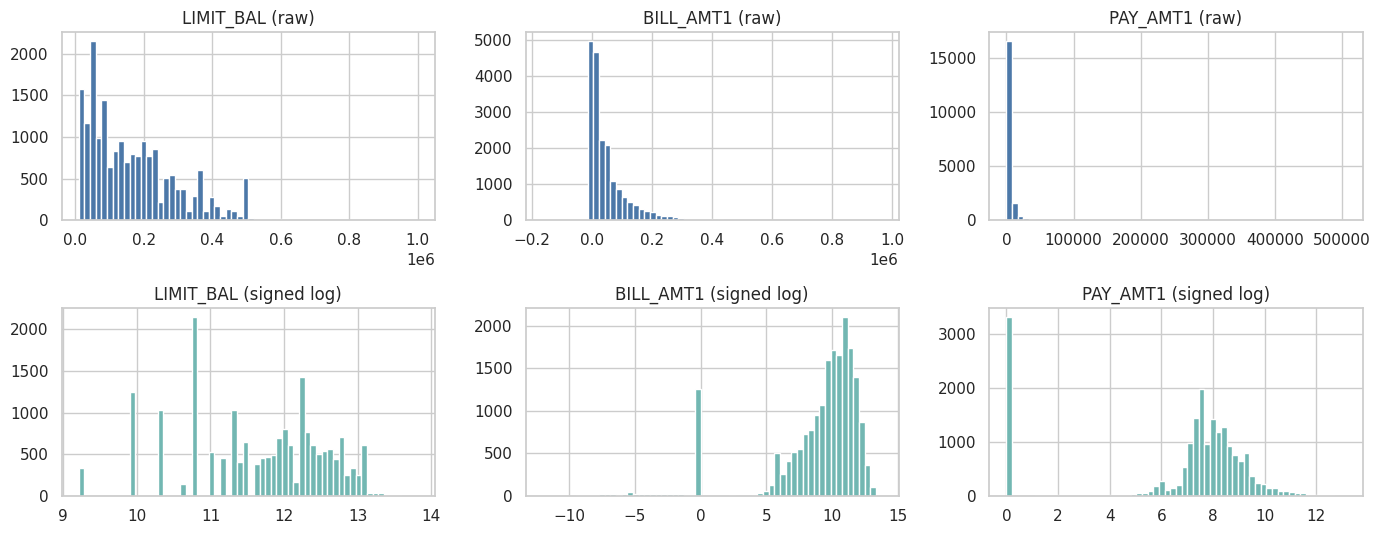

In [ ]:
def signed_log(a):
    a = np.asarray(a, dtype=float); return np.sign(a) * np.log1p(np.abs(a))
money = ['LIMIT_BAL'] + bill_cols + pay_amt_cols
skew = pd.DataFrame({'raw': X_train[money].skew(), 'signed_log': pd.DataFrame(signed_log(X_train[money]), columns=money).skew()}).round(2)
display(skew.T)
RESULTS['skew_raw_max'] = float(skew['raw'].max()); RESULTS['skew_log_maxabs'] = float(skew['signed_log'].abs().max())
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for j, col in enumerate(['LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1']):
    axes[0, j].hist(X_train[col], bins=60, color='#4C78A8'); axes[0, j].set_title(f'{col} (raw)')
    axes[1, j].hist(signed_log(X_train[col]), bins=60, color='#72B7B2'); axes[1, j].set_title(f'{col} (signed log)')
plt.tight_layout(); plt.savefig('figures/fig_skew.png', dpi=130, bbox_inches='tight'); plt.show()

### 3.3 The feature-preparation transformer

All cleaning and feature creation sits in one scikit-learn transformer, `CreditFeatures`, so it can be put in front of any model and refitted per fold. Options: `engineered` (`False`, `True` for the Week-5 set, or `'extended'` which adds four more features suggested in the Week-5 plan), `bins` (`'none'`, `'both'`, `'only'`), `drop_raw_history` and `drop_sensitive` (removes `SEX`, `AGE`, `MARRIAGE` and the age bin, used in the sensitive-attribute comparison). Only the credit-limit quantile bin edges are learned from data, from the training rows passed to `fit`.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin, clone

class CreditFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, engineered=True, bins='none', drop_raw_history=False, drop_sensitive=False):
        self.engineered = engineered; self.bins = bins; self.drop_raw_history = drop_raw_history; self.drop_sensitive = drop_sensitive
    @staticmethod
    def _clean(X):
        X = X.copy()
        X['EDUCATION'] = X['EDUCATION'].replace({0: 4, 5: 4, 6: 4}); X['MARRIAGE'] = X['MARRIAGE'].replace({0: 3})
        return X
    def fit(self, X, y=None):
        X = self._clean(X)
        self.age_edges_ = np.array([25, 35, 50, 65])
        self.limit_edges_ = np.unique(np.quantile(X['LIMIT_BAL'], [0.2, 0.4, 0.6, 0.8]))   # learned on training rows only
        return self
    def transform(self, X):
        X = self._clean(X)
        pay, bill, amt = X[pay_cols], X[bill_cols], X[pay_amt_cols]; limit = X['LIMIT_BAL'].values
        if self.engineered:
            delay = pay.clip(lower=0)
            X['max_delay'] = delay.max(axis=1); X['n_delayed'] = (pay > 0).sum(axis=1)
            X['delay_recent3'] = delay[['PAY_1', 'PAY_2', 'PAY_3']].mean(axis=1); X['delay_older3'] = delay[['PAY_4', 'PAY_5', 'PAY_6']].mean(axis=1)
            util = np.clip(bill.values / limit[:, None], -1, 2)
            X['util_1'] = util[:, 0]; X['avg_util'] = util.mean(axis=1)
            prev, paid = bill.values[:, 1:], amt.values[:, :5]                  # payment in month k settles the bill of month k+1
            ratio = np.clip(np.where(prev > 0, paid / np.where(prev > 0, prev, 1.0), 1.0), 0, 5)
            X['pay_ratio_1'] = ratio[:, 0]; X['avg_pay_ratio'] = ratio.mean(axis=1)
            X['bill_trend'] = np.clip((bill['BILL_AMT1'].values - bill['BILL_AMT6'].values) / limit, -2, 2)
            X['n_zero_pay'] = (amt == 0).sum(axis=1)
            if self.engineered == 'extended':
                X['delay_trend'] = X['delay_recent3'] - X['delay_older3']
                X['delay_x_unpaid'] = X['max_delay'] * (1 - np.clip(X['avg_pay_ratio'], 0, 1))
                X['pay_ratio_min'] = ratio.min(axis=1)
                X['util_change'] = util[:, 0] - util[:, 5]
        if self.bins in ('both', 'only'):
            X['AGE_BIN'] = np.digitize(X['AGE'], self.age_edges_); X['LIMIT_BIN'] = np.digitize(X['LIMIT_BAL'], self.limit_edges_)
            if self.bins == 'only': X = X.drop(columns=['AGE', 'LIMIT_BAL'])
        if self.drop_raw_history:
            X = X.drop(columns=[f'BILL_AMT{i}' for i in range(2, 7)] + [f'PAY_AMT{i}' for i in range(2, 7)])
        if self.drop_sensitive:
            X = X.drop(columns=[c for c in ['SEX', 'AGE', 'MARRIAGE', 'AGE_BIN'] if c in X.columns])
        return X

demo = CreditFeatures(engineered='extended', bins='both').fit(X_train)
print('Age edges:', demo.age_edges_, '| credit-limit quantile edges (train):', demo.limit_edges_)
print('Columns produced:', list(demo.transform(X_train.head(2)).columns))

Age edges: [25 35 50 65] | credit-limit quantile edges (train): [ 50000. 100000. 180000. 280000.]
Columns produced: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'max_delay', 'n_delayed', 'delay_recent3', 'delay_older3', 'util_1', 'avg_util', 'pay_ratio_1', 'avg_pay_ratio', 'bill_trend', 'n_zero_pay', 'delay_trend', 'delay_x_unpaid', 'pay_ratio_min', 'util_change', 'AGE_BIN', 'LIMIT_BIN']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

CAT_SET = {'SEX', 'EDUCATION', 'MARRIAGE', 'AGE_BIN', 'LIMIT_BIN'}
def cat_sel(X): return [c for c in X.columns if c in CAT_SET]
def amt_sel(X): return [c for c in X.columns if c.startswith(('BILL_AMT', 'PAY_AMT')) or c == 'LIMIT_BAL']
def num_sel(X): return [c for c in X.columns if c not in CAT_SET and c not in amt_sel(X)]

def lr_pipeline(fc, **lr_kw):
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_sel),
                             ('amt', Pipeline([('log', FunctionTransformer(signed_log)), ('sc', StandardScaler())]), amt_sel),
                             ('num', StandardScaler(), num_sel)])
    return Pipeline([('feat', CreditFeatures(**fc)), ('prep', pre), ('model', LogisticRegression(max_iter=3000, **lr_kw))])
def tree_pipeline(fc, est): return Pipeline([('feat', CreditFeatures(**fc)), ('model', est)])
def lgbm(**kw):
    base = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                random_state=RANDOM_STATE, verbose=-1, n_jobs=1)
    base.update(kw); return LGBMClassifier(**base)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)   # 15 paired folds
SCORING = {'ap': 'average_precision', 'auc': 'roc_auc'}
def rep_eval(model, cv_=cv_rep, train_score=False):
    s = cross_validate(model, X_train, y_train, cv=cv_, scoring=SCORING, return_train_score=train_score, n_jobs=1)
    return {k: np.asarray(v) for k, v in s.items()}

### 3.4 Feature-engineering experiments

Feature groups are tested one at a time with **repeated stratified 5-fold CV (5 × 3 = 15 folds)** using Logistic Regression and LightGBM. Variants: raw columns; the Week-5 engineered set; engineered + age/limit bins (from the course note on binning; edges learned on training rows only); and the extended set with four extra features (`delay_trend`, `delay_x_unpaid`, `pay_ratio_min`, `util_change`).

**Selection rule (fixed in advance):** use the extended set only if it beats the Week-5 set in mean AP for LightGBM by at least 0.002 *and* does not lower Logistic Regression's mean AP; otherwise keep the Week-5 set.

,LR AP,LR AP sd,LR AUC,LGBM AP,LGBM AP sd,LGBM AUC
Variant,,,,,,
F0 raw columns,0.4987,0.0127,0.7418,0.5551,0.0138,0.7815
F1 engineered (Week 5),0.5121,0.0107,0.7618,0.5567,0.0131,0.7843
F2 engineered + bins,0.5112,0.0108,0.7609,0.5572,0.0136,0.7842
F3 extended,0.5131,0.0110,0.7622,0.5562,0.0133,0.7839


Extended vs Week-5 set: LightGBM -0.0005, LR +0.0011  ->  selected feature config: {'engineered': True, 'bins': 'none'}


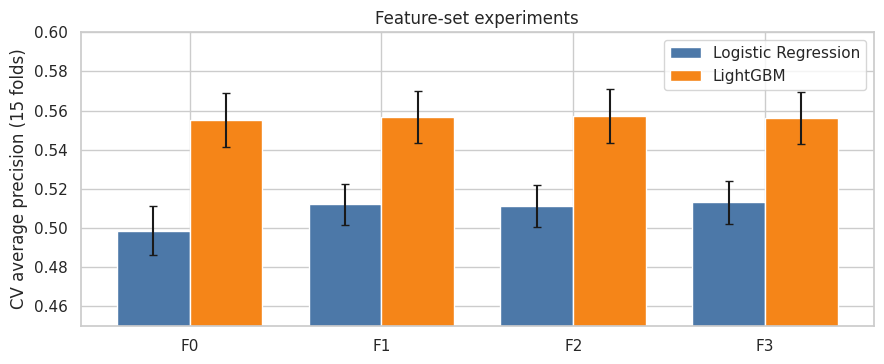

In [ ]:
fe_variants = {'F0 raw columns': dict(engineered=False, bins='none'),
               'F1 engineered (Week 5)': dict(engineered=True, bins='none'),
               'F2 engineered + bins': dict(engineered=True, bins='both'),
               'F3 extended': dict(engineered='extended', bins='none')}
def _fe():
    out = {}
    for name, kw in fe_variants.items():
        out[name] = {'LR': rep_eval(lr_pipeline(kw)), 'LGBM': rep_eval(tree_pipeline(kw, lgbm()))}
    return out
fe_res = cached('fe_experiments', _fe)
rows = []
for name, r in fe_res.items():
    rows.append({'Variant': name, 'LR AP': r['LR']['test_ap'].mean(), 'LR AP sd': r['LR']['test_ap'].std(), 'LR AUC': r['LR']['test_auc'].mean(),
                 'LGBM AP': r['LGBM']['test_ap'].mean(), 'LGBM AP sd': r['LGBM']['test_ap'].std(), 'LGBM AUC': r['LGBM']['test_auc'].mean()})
fe_table = pd.DataFrame(rows).set_index('Variant'); display(fe_table.round(4))
RESULTS['fe_table'] = fe_table.round(4).reset_index().to_dict('records')
gain_lgbm = fe_table.loc['F3 extended', 'LGBM AP'] - fe_table.loc['F1 engineered (Week 5)', 'LGBM AP']
gain_lr = fe_table.loc['F3 extended', 'LR AP'] - fe_table.loc['F1 engineered (Week 5)', 'LR AP']
use_ext = (gain_lgbm >= 0.002) and (gain_lr >= 0)
FC = dict(engineered='extended' if use_ext else True, bins='none')
print(f'Extended vs Week-5 set: LightGBM {gain_lgbm:+.4f}, LR {gain_lr:+.4f}  ->  selected feature config: {FC}')
RESULTS['fc'] = {k: str(v) for k, v in FC.items()}; RESULTS['fe_gain_lgbm'] = float(gain_lgbm); RESULTS['fe_gain_lr'] = float(gain_lr)

fig, ax = plt.subplots(figsize=(9, 3.8)); idx = np.arange(len(fe_table)); w = 0.38
ax.bar(idx - w/2, fe_table['LR AP'], w, yerr=fe_table['LR AP sd'], label='Logistic Regression', color='#4C78A8', capsize=3)
ax.bar(idx + w/2, fe_table['LGBM AP'], w, yerr=fe_table['LGBM AP sd'], label='LightGBM', color='#F58518', capsize=3)
ax.set_xticks(idx); ax.set_xticklabels([v.split(' ')[0] for v in fe_table.index]); ax.set_ylim(0.45, 0.60)
ax.set_ylabel('CV average precision (15 folds)'); ax.set_title('Feature-set experiments'); ax.legend()
plt.tight_layout(); plt.savefig('figures/fig_fe.png', dpi=130, bbox_inches='tight'); plt.show()

**Observations (CV average precision over 15 paired folds; fold standard deviation about 0.011–0.014).**
- **Engineered features help the linear model clearly and the tree model slightly.** Logistic Regression rises from 0.499 to 0.512 AP (AUC 0.742 → 0.762). LightGBM rises from 0.555 to 0.557, well inside the fold noise, which fits the expectation that trees can already combine raw columns.
- **Binning gives no measurable benefit.** Adding age and limit bins changes AP by −0.001 (Logistic Regression) and +0.0005 (LightGBM). Age carries almost no signal here (correlation 0.01) and credit limit is already close to monotone, so there was little for bins to add. The binning note's reasoning for linear models (step-like risk) did not show up in this dataset.
- **The four extra features did not pass the pre-set rule.** The extended set changes AP by +0.0011 for Logistic Regression and −0.0005 for LightGBM, so the Week-5 engineered set is kept. `delay_x_unpaid` correlates with default at 0.35 but largely repeats information in `max_delay` (0.36).

**Decision:** Week-5 engineered features, no bins, full monthly history.

## 4. Exploratory Data Analysis

EDA uses the training split only. Questions: how default varies with delay, credit limit, age and utilisation; whether the monthly bills are redundant; whether the engineered features carry signal.

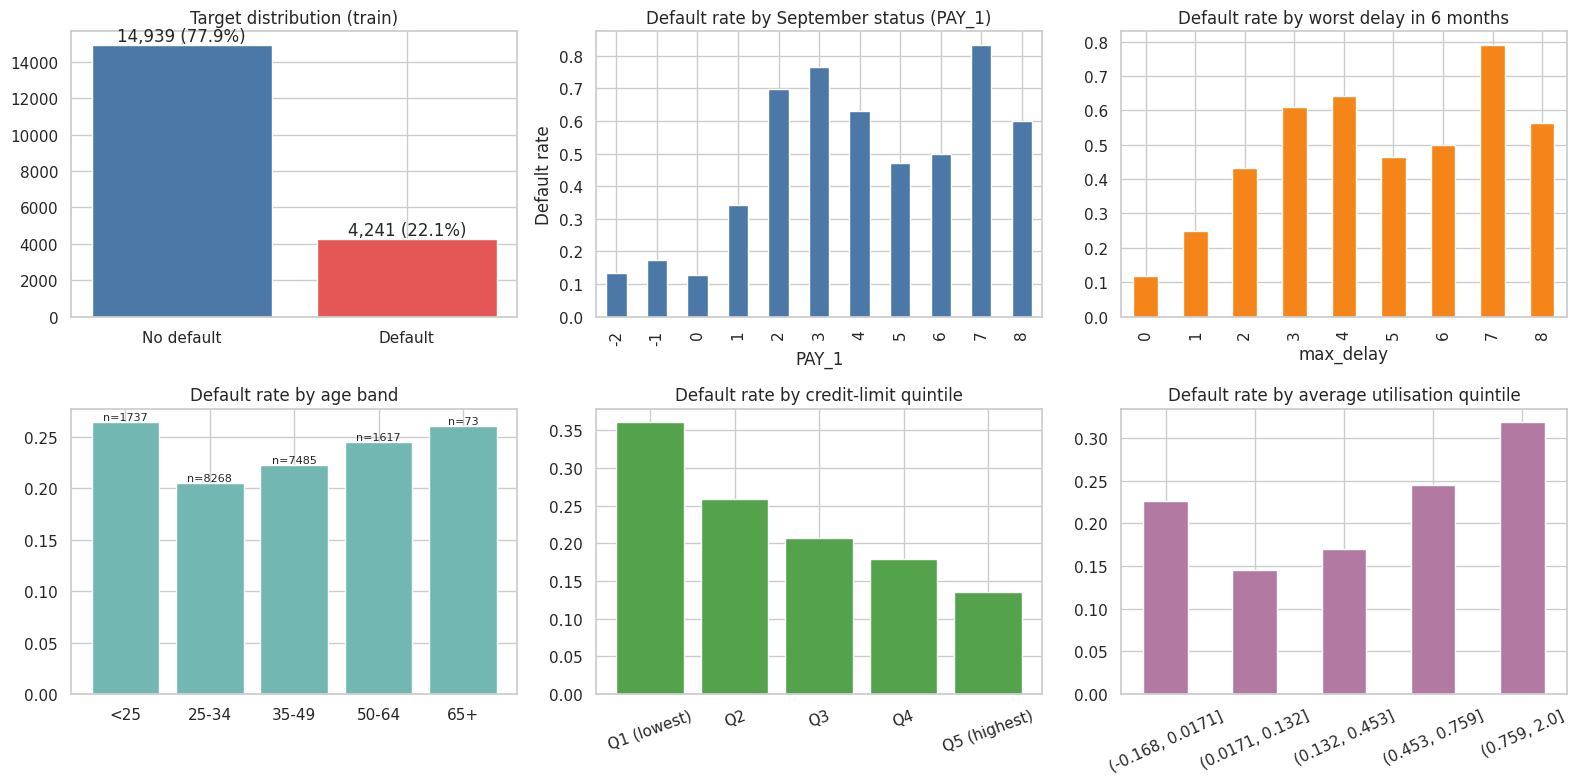

Customers by PAY_1 status: {-2: 1745, -1: 3686, 0: 9442, 1: 2341, 2: 1685, 3: 196, 4: 46, 5: 17, 6: 6, 7: 6, 8: 10}


In [ ]:
train = X_train.assign(default=y_train)
Ftr = CreditFeatures(engineered='extended', bins='both').fit(X_train).transform(X_train); Ftr['default'] = y_train.values
age_labels = ['<25', '25-34', '35-49', '50-64', '65+']; lim_labels = ['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
cnt = y_train.value_counts().sort_index()
axes[0, 0].bar(['No default', 'Default'], cnt.values, color=['#4C78A8', '#E45756'])
for i, v in enumerate(cnt.values): axes[0, 0].text(i, v, f'{v:,} ({v/len(y_train):.1%})', ha='center', va='bottom')
axes[0, 0].set_title('Target distribution (train)')
train.groupby('PAY_1')['default'].mean().plot.bar(ax=axes[0, 1], color='#4C78A8'); axes[0, 1].set_title('Default rate by September status (PAY_1)'); axes[0, 1].set_ylabel('Default rate')
Ftr.groupby('max_delay')['default'].mean().plot.bar(ax=axes[0, 2], color='#F58518'); axes[0, 2].set_title('Default rate by worst delay in 6 months')
g = Ftr.groupby('AGE_BIN')['default'].agg(['mean', 'size']); axes[1, 0].bar(age_labels, g['mean'].values, color='#72B7B2'); axes[1, 0].set_title('Default rate by age band')
for i, (m, n) in enumerate(zip(g['mean'], g['size'])): axes[1, 0].text(i, m, f'n={n}', ha='center', va='bottom', fontsize=8)
g = Ftr.groupby('LIMIT_BIN')['default'].agg(['mean', 'size']); axes[1, 1].bar(lim_labels, g['mean'].values, color='#54A24B'); axes[1, 1].set_title('Default rate by credit-limit quintile'); axes[1, 1].tick_params(axis='x', rotation=20)
Ftr['util_band'] = pd.qcut(Ftr['avg_util'], 5, duplicates='drop')
Ftr.groupby('util_band', observed=True)['default'].mean().plot.bar(ax=axes[1, 2], color='#B279A2'); axes[1, 2].set_title('Default rate by average utilisation quintile'); axes[1, 2].set_xlabel(''); axes[1, 2].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.savefig('figures/fig_eda.png', dpi=130, bbox_inches='tight'); plt.show()
RESULTS['eda'] = {'pay1': train.groupby('PAY_1')['default'].mean().round(3).to_dict(), 'maxdelay': Ftr.groupby('max_delay')['default'].mean().round(3).to_dict(),
                  'age': dict(zip(age_labels, Ftr.groupby('AGE_BIN')['default'].mean().round(3))), 'limit': dict(zip(lim_labels, Ftr.groupby('LIMIT_BIN')['default'].mean().round(3))),
                  'util': Ftr.groupby('util_band', observed=True)['default'].mean().round(3).tolist()}
print('Customers by PAY_1 status:', train['PAY_1'].value_counts().sort_index().to_dict())

,n_delayed,delay_recent3,max_delay,delay_x_unpaid,PAY_1,delay_older3,PAY_2,n_zero_pay,LIMIT_BAL,avg_util,delay_trend,avg_pay_ratio,pay_ratio_1,util_1,pay_ratio_min,util_change,bill_trend,AGE
correlation with default,0.391,0.379,0.362,0.353,0.322,0.284,0.25,0.162,-0.152,0.121,0.12,-0.102,-0.091,0.091,-0.086,-0.026,-0.026,0.012


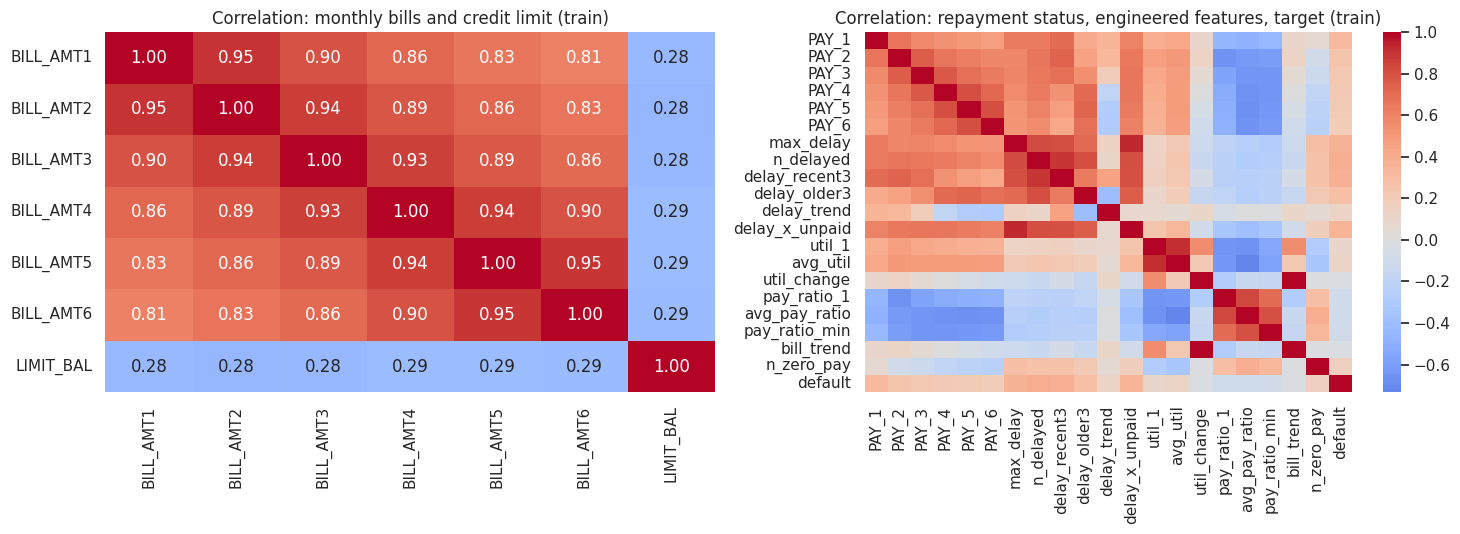

In [ ]:
num_eng = ['max_delay', 'n_delayed', 'delay_recent3', 'delay_older3', 'delay_trend', 'delay_x_unpaid', 'util_1', 'avg_util', 'util_change', 'pay_ratio_1', 'avg_pay_ratio', 'pay_ratio_min', 'bill_trend', 'n_zero_pay']
corr_t = Ftr[num_eng + ['PAY_1', 'PAY_2', 'LIMIT_BAL', 'AGE', 'default']].corr()['default'].drop('default').sort_values(key=abs, ascending=False)
display(corr_t.round(3).to_frame('correlation with default').T); RESULTS['corr_target'] = corr_t.round(3).to_dict()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(train[bill_cols + ['LIMIT_BAL']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1, ax=axes[0], cbar=False); axes[0].set_title('Correlation: monthly bills and credit limit (train)')
sns.heatmap(Ftr[pay_cols + num_eng + ['default']].corr(), cmap='coolwarm', center=0, ax=axes[1]); axes[1].set_title('Correlation: repayment status, engineered features, target (train)')
plt.tight_layout(); plt.savefig('figures/fig_corr.png', dpi=130, bbox_inches='tight'); plt.show()
bc = train[bill_cols].corr().values; RESULTS['bill_corr_min'] = float(bc[np.triu_indices(6, 1)].min()); RESULTS['bill_corr_adj_min'] = float(min(bc[i, i + 1] for i in range(5)))

**Observations (training split; descriptive, not causal).**
- **Repayment delay dominates.** Default is 12.7–17.3% for September statuses −2, −1 and 0, jumps to 34% at a one-month delay and about 70% at two months. The worst delay in six months rises from 11.9% (none) to 24.8%, 43.3% and 61.1% at one, two and three months. Beyond three months the groups are small (46 customers at four months and 17 or fewer at each later value), so those rates are noisy.
- **Credit limit is monotone:** 36.0% default in the lowest quintile to 13.5% in the highest.
- **Age is weak and U-shaped:** 26.4% under 25, 20.5% at 25–34, 22.3% at 35–49, 24.5% at 50–64, 26.0% at 65+ (73 customers).
- **Utilisation is not monotone** (22.7%, 14.5%, 17.0%, 24.5%, 31.9% by quintile); the lowest quintile includes negative (credit-balance) utilisation, not investigated further.
- **Redundancy:** every pair of monthly bills correlates at 0.81 or more (adjacent months 0.93 or more). Delay summaries correlate with default more than any single raw status column (`n_delayed` 0.39, `delay_recent3` 0.38, `max_delay` 0.36, against 0.32 for `PAY_1`); `AGE` is 0.01.

## 5. Baseline & Improved Models

Baselines use the **raw columns** (cleaned codes only, no engineered features), as proposed in Week 2: a Dummy classifier and Logistic Regression, plain and class-balanced (5-fold CV on the training split; precision, recall and F1 at the 0.5 threshold). The improved models then use the selected feature set with reasonable default settings, ahead of tuning in section 6.

In [ ]:
base_scoring = {'roc_auc': 'roc_auc', 'average_precision': 'average_precision', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'accuracy': 'accuracy'}
V0 = dict(engineered=False, bins='none')
baselines = {'Dummy (prior)': Pipeline([('feat', CreditFeatures(**V0)), ('model', DummyClassifier(strategy='prior'))]),
             'Logistic Regression': lr_pipeline(V0), 'Logistic Regression (balanced)': lr_pipeline(V0, class_weight='balanced')}
def _base():
    out = {}
    for name, m in baselines.items():
        s = cross_validate(m, X_train, y_train, cv=cv5, scoring=base_scoring, n_jobs=1)
        out[name] = {k: (float(s['test_' + k].mean()), float(s['test_' + k].std())) for k in base_scoring}
    return out
base_res = cached('baseline', _base)
display(pd.DataFrame({n: {k: f'{m:.3f} ± {s:.3f}' for k, (m, s) in r.items()} for n, r in base_res.items()}).T)
RESULTS['baseline'] = {n: {k: [m, s] for k, (m, s) in r.items()} for n, r in base_res.items()}

,roc_auc,average_precision,precision,recall,f1,accuracy
Dummy (prior),0.500 ± 0.000,0.221 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.779 ± 0.000
Logistic Regression,0.742 ± 0.011,0.499 ± 0.016,0.664 ± 0.017,0.232 ± 0.014,0.344 ± 0.016,0.804 ± 0.003
Logistic Regression (balanced),0.746 ± 0.011,0.493 ± 0.016,0.428 ± 0.010,0.628 ± 0.017,0.509 ± 0.009,0.732 ± 0.008


**Interpretation.** The Dummy model has 77.9% accuracy but finds no defaulters, so accuracy is not a useful guide. Plain Logistic Regression ranks customers reasonably (ROC-AUC 0.742, AP 0.499) but at the 0.5 threshold catches only 23% of defaulters (precision 0.66). Balanced class weights barely change the ranking (AUC 0.746, AP 0.493) but raise recall to 63% at a precision of 0.43: the threshold, not the model, controls the recall–precision trade-off. These are the numbers the final model is measured against.

In [ ]:
def build(name, params=None, fc=None, **kw):
    fc = fc or FC
    if name == 'Logistic Regression': pipe = lr_pipeline(fc)
    elif name == 'Random Forest': pipe = tree_pipeline(fc, RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features='sqrt', random_state=RANDOM_STATE, n_jobs=1))
    elif name == 'Gradient Boosting': pipe = tree_pipeline(fc, GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=RANDOM_STATE))
    elif name == 'AdaBoost': pipe = tree_pipeline(fc, AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE))
    elif name == 'XGBoost': pipe = tree_pipeline(fc, XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=1, tree_method='hist'))
    elif name == 'LightGBM': pipe = tree_pipeline(fc, lgbm())
    else: raise ValueError(name)
    if params: pipe.set_params(**params)
    return pipe
MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'AdaBoost', 'XGBoost', 'LightGBM']

def _defaults():
    out = {}
    for n in MODEL_NAMES:
        t0 = time.time(); s = rep_eval(build(n), cv_=cv5, train_score=True)
        out[n] = {'AP': s['test_ap'].mean(), 'AP_sd': s['test_ap'].std(), 'AUC': s['test_auc'].mean(), 'train_AP': s['train_ap'].mean(), 'sec': time.time() - t0}
    return out
dres = cached('default_models', _defaults)
default_table = pd.DataFrame(dres).T; default_table['AP gap (train - CV)'] = default_table['train_AP'] - default_table['AP']
default_table = default_table.sort_values('AP', ascending=False); display(default_table.round(4))
RESULTS['defaults'] = default_table.round(4).reset_index().rename(columns={'index': 'Model'}).to_dict('records')

,AP,AP_sd,AUC,train_AP,sec,AP gap (train - CV)
LightGBM,0.5557,0.0139,0.7842,0.6847,5.3941,0.1290
XGBoost,0.5545,0.0122,0.7838,0.6886,5.3893,0.1342
Gradient Boosting,0.5519,0.0123,0.7832,0.6447,79.0147,0.0928
Random Forest,0.5485,0.0110,0.7778,0.8987,105.8457,0.3502
AdaBoost,0.5358,0.0099,0.7770,0.5483,52.8047,0.0125
Logistic Regression,0.5119,0.0124,0.7624,0.5165,2.3683,0.0046


**Observations (5-fold CV, default-style settings).** LightGBM 0.556, XGBoost 0.555, Gradient Boosting 0.553 and Random Forest 0.549 lie within 0.007 of each other, less than one fold standard deviation (0.011–0.014); AdaBoost (0.536) and Logistic Regression (0.512) are lower. Random Forest memorises its training data (train AP 0.90 against 0.55 held out, gap 0.35) even with `min_samples_leaf=5`; LightGBM and XGBoost show gaps of about 0.13, Gradient Boosting 0.09; AdaBoost and Logistic Regression barely overfit but have less capacity. LightGBM and XGBoost need 3–4 seconds per 5-fold run against 26–41 seconds for the other ensembles.

## 6. Hyperparameter Tuning

Every model gets a tuning attempt, scored by CV average precision on the training split:
- **Logistic Regression:** grid over `C` and class weights.
- **LightGBM, XGBoost:** `RandomizedSearchCV`, **30 trials × 5 folds**, with ranges narrowed around the Week-5 best region (learning rate about 0.015–0.06, XGBoost depth 3–5).
- **Random Forest, Gradient Boosting, AdaBoost** (new in the final): `RandomizedSearchCV` with 10, 10 and 8 trials. Because these are 5–10 times slower per fit on one CPU core, they use **3-fold CV** to keep the budget; their final comparison with the other models uses the same repeated 5-fold CV in section 7.

Random search is used because only a few settings usually matter strongly, and random draws try more distinct values of each than a grid with the same budget. Every trial is logged.

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def run_search(name, pipe, space, n_iter, cv_):
    def _go():
        t0 = time.time()
        rs = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring='average_precision', cv=cv_, random_state=RANDOM_STATE, n_jobs=1, refit=False, return_train_score=True)
        rs.fit(X_train, y_train); res = pd.DataFrame(rs.cv_results_)
        return {'results': res, 'best_params': plain(rs.best_params_), 'best_score': float(rs.best_score_),
                'best_sd': float(res.loc[rs.best_index_, 'std_test_score']), 'best_train': float(res.loc[rs.best_index_, 'mean_train_score']),
                'sec': time.time() - t0, 'n_iter': n_iter, 'folds': cv_.get_n_splits()}
    return cached('search_' + name, _go)

# 6.1 Logistic Regression grid
def _lr():
    gs = GridSearchCV(lr_pipeline(FC), {'model__C': [0.01, 0.1, 1, 10], 'model__class_weight': [None, 'balanced']}, scoring='average_precision', cv=cv5, n_jobs=1, refit=False)
    gs.fit(X_train, y_train); res = pd.DataFrame(gs.cv_results_)
    return {'results': res, 'best_params': plain(gs.best_params_), 'best_score': float(gs.best_score_), 'best_sd': float(res.loc[gs.best_index_, 'std_test_score']),
            'n_iter': 8, 'folds': 5}
S = {'Logistic Regression': cached('search_lr', _lr)}
lr_log = S['Logistic Regression']['results'][['param_model__C', 'param_model__class_weight', 'mean_test_score', 'std_test_score']].copy()
lr_log.columns = ['C', 'class_weight', 'CV AP', 'sd']; lr_log['class_weight'] = lr_log['class_weight'].astype(str)
display(lr_log.sort_values('CV AP', ascending=False).round(4))

,C,class_weight,CV AP,sd
2,0.10,None,0.5121,0.0125
4,1.00,None,0.5119,0.0124
6,10.00,None,0.5119,0.0125
0,0.01,None,0.5109,0.0128
3,0.10,balanced,0.5077,0.0118
5,1.00,balanced,0.5076,0.0117
7,10.00,balanced,0.5076,0.0117
1,0.01,balanced,0.5071,0.0125


In [ ]:
# 6.2 LightGBM and XGBoost (refined around the Week-5 best region)
lgbm_space = {'model__n_estimators': randint(150, 500), 'model__learning_rate': loguniform(0.015, 0.06), 'model__num_leaves': randint(8, 40),
              'model__min_child_samples': randint(20, 120), 'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.5, 0.5),
              'model__reg_lambda': loguniform(1e-2, 10), 'model__scale_pos_weight': [1, 2, 3.5, 5]}
xgb_space = {'model__n_estimators': randint(150, 500), 'model__learning_rate': loguniform(0.015, 0.06), 'model__max_depth': randint(3, 6),
             'model__min_child_weight': randint(1, 20), 'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.5, 0.5),
             'model__reg_lambda': loguniform(1e-2, 10), 'model__scale_pos_weight': [1, 2, 3.5, 5]}
S['LightGBM'] = run_search('lgbm', build('LightGBM'), lgbm_space, 30, cv5)
S['XGBoost'] = run_search('xgb', build('XGBoost'), xgb_space, 30, cv5)
for n in ['LightGBM', 'XGBoost']:
    print(f"{n}: best CV AP {S[n]['best_score']:.4f} ± {S[n]['best_sd']:.4f} (defaults {dres[n]['AP']:.4f}) in {S[n]['sec']:.0f}s")
    print('   ', {k.replace('model__', ''): round(v, 4) for k, v in S[n]['best_params'].items()})

LightGBM: best CV AP 0.5580 ± 0.0127 (defaults 0.5557) in 279s
    {'colsample_bytree': 0.5404, 'learning_rate': 0.025, 'min_child_samples': 36, 'n_estimators': 404, 'num_leaves': 13, 'reg_lambda': 0.1269, 'scale_pos_weight': 5, 'subsample': 0.9934}
XGBoost: best CV AP 0.5577 ± 0.0120 (defaults 0.5545) in 166s
    {'colsample_bytree': 0.7283, 'learning_rate': 0.0203, 'max_depth': 4, 'min_child_weight': 11, 'n_estimators': 277, 'reg_lambda': 2.6444, 'scale_pos_weight': 5, 'subsample': 0.7425}


In [ ]:
# 6.3 Random Forest, Gradient Boosting, AdaBoost (new in the final submission; 3-fold CV for budget)
rf_space = {'model__n_estimators': randint(150, 350), 'model__max_depth': [6, 8, 10, 14, 18], 'model__min_samples_leaf': randint(5, 40),
            'model__max_features': ['sqrt', 0.2, 0.35], 'model__class_weight': [None, 'balanced_subsample']}
gb_space = {'model__n_estimators': randint(80, 250), 'model__learning_rate': loguniform(0.03, 0.15), 'model__max_depth': randint(2, 5),
            'model__subsample': uniform(0.6, 0.4), 'model__min_samples_leaf': randint(10, 80)}
ada_space = {'model__n_estimators': randint(100, 400), 'model__learning_rate': loguniform(0.05, 1.0), 'model__estimator__max_depth': randint(1, 4)}
S['Random Forest'] = run_search('rf', build('Random Forest'), rf_space, 10, cv3)
S['Gradient Boosting'] = run_search('gb', build('Gradient Boosting'), gb_space, 10, cv3)
S['AdaBoost'] = run_search('ada', build('AdaBoost'), ada_space, 8, cv3)
for n in ['Random Forest', 'Gradient Boosting', 'AdaBoost']:
    print(f"{n}: best {S[n]['folds']}-fold CV AP {S[n]['best_score']:.4f} in {S[n]['sec']:.0f}s")
    print('   ', {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in S[n]['best_params'].items()})

Random Forest: best 3-fold CV AP 0.5501 in 404s
    {'class_weight': None, 'max_depth': 8, 'max_features': 0.35, 'min_samples_leaf': 11, 'n_estimators': 321}
Gradient Boosting: best 3-fold CV AP 0.5529 in 381s
    {'learning_rate': 0.0403, 'max_depth': 3, 'min_samples_leaf': 31, 'n_estimators': 168, 'subsample': 0.7165}
AdaBoost: best 3-fold CV AP 0.5468 in 604s
    {'estimator__max_depth': 3, 'learning_rate': 0.0532, 'n_estimators': 357}


,Search,AP default (5-fold),AP best trial,trial range,median trial
Model,,,,,
Logistic Regression,8 settings x 5-fold,0.5119,0.5121,0.507-0.512,0.5093
Random Forest,10 trials x 3-fold,0.5485,0.5501,0.548-0.550,0.5491
Gradient Boosting,10 trials x 3-fold,0.5519,0.5529,0.541-0.553,0.5496
AdaBoost,8 trials x 3-fold,0.5358,0.5468,0.535-0.547,0.5410
XGBoost,30 trials x 5-fold,0.5545,0.5577,0.543-0.558,0.5557
LightGBM,30 trials x 5-fold,0.5557,0.5580,0.532-0.558,0.5543


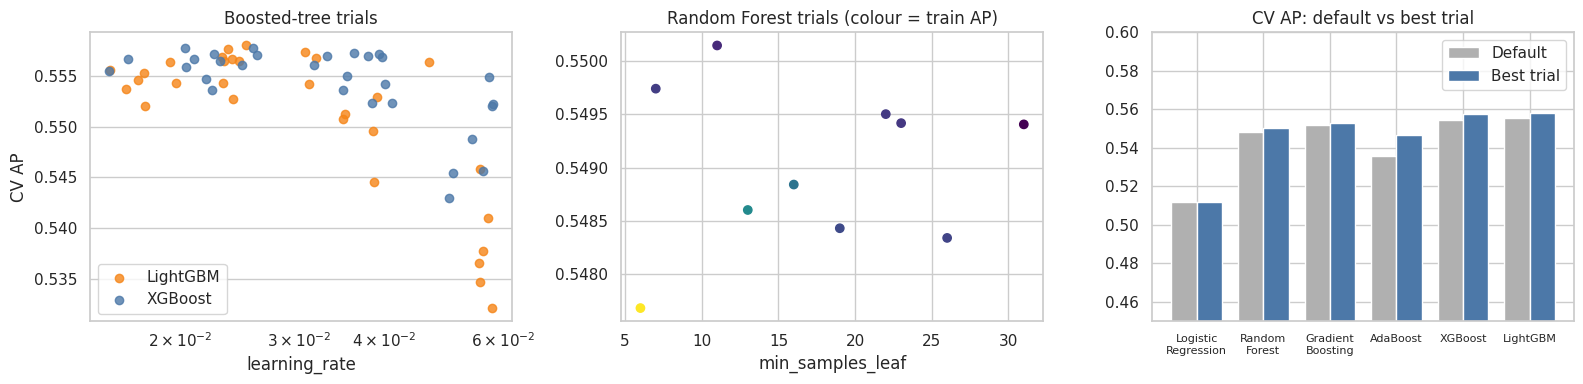

In [ ]:
TUNED = {n: S[n]['best_params'] for n in MODEL_NAMES}
rows = []
for n in MODEL_NAMES:
    res = S[n]['results']; start = dres[n]['AP']
    rows.append({'Model': n, 'Search': f"{S[n]['n_iter']} {'settings' if n == 'Logistic Regression' else 'trials'} x {S[n]['folds']}-fold",
                 'AP default (5-fold)': start, 'AP best trial': S[n]['best_score'], 'trial range': f"{res['mean_test_score'].min():.3f}-{res['mean_test_score'].max():.3f}",
                 'median trial': res['mean_test_score'].median()})
tune_table = pd.DataFrame(rows).set_index('Model'); display(tune_table.round(4))
RESULTS['tuning'] = {n: {'best_params': {k.replace('model__', ''): (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in S[n]['best_params'].items()},
                         'best': S[n]['best_score'], 'best_sd': S[n]['best_sd'], 'default': float(dres[n]['AP']), 'min': float(S[n]['results']['mean_test_score'].min()),
                         'median': float(S[n]['results']['mean_test_score'].median()), 'n_iter': S[n]['n_iter'], 'folds': S[n]['folds'], 'sec': S[n].get('sec', 0)} for n in MODEL_NAMES}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for n, c_ in [('LightGBM', '#F58518'), ('XGBoost', '#4C78A8')]:
    r = S[n]['results']; axes[0].scatter(r['param_model__learning_rate'].astype(float), r['mean_test_score'], label=n, color=c_, alpha=0.8)
axes[0].set_xscale('log'); axes[0].set_xlabel('learning_rate'); axes[0].set_ylabel('CV AP'); axes[0].set_title('Boosted-tree trials'); axes[0].legend()
r = S['Random Forest']['results']; axes[1].scatter(r['param_model__min_samples_leaf'].astype(float), r['mean_test_score'], c=r['mean_train_score'], cmap='viridis')
axes[1].set_xlabel('min_samples_leaf'); axes[1].set_title('Random Forest trials (colour = train AP)')
x = np.arange(len(MODEL_NAMES)); w = 0.38
axes[2].bar(x - w/2, [dres[n]['AP'] for n in MODEL_NAMES], w, label='Default', color='#B0B0B0'); axes[2].bar(x + w/2, [S[n]['best_score'] for n in MODEL_NAMES], w, label='Best trial', color='#4C78A8')
axes[2].set_xticks(x); axes[2].set_xticklabels([n.replace(' ', '\n') for n in MODEL_NAMES], fontsize=8); axes[2].set_ylim(0.45, 0.6); axes[2].set_title('CV AP: default vs best trial'); axes[2].legend()
plt.tight_layout(); plt.savefig('figures/fig_tuning.png', dpi=130, bbox_inches='tight'); plt.show()

**Observations.**
- **Logistic Regression:** `C` from 0.01 to 10 changes AP by at most 0.001 (best 0.5121 at C = 0.1, no weights). Balanced weights lower AP slightly (about 0.508), because weights mostly shift the threshold and do not improve ranking.
- **LightGBM and XGBoost (30 trials, 5-fold):** best 0.5580 and 0.5577 against 0.5557 and 0.5545 for the defaults (+0.0023 and +0.0032). Trial scores ranged from 0.532 to 0.558 (LightGBM) and 0.543 to 0.558 (XGBoost), so many random settings were worse than the defaults. Both best settings use a low learning rate (0.025 and 0.020) and the largest positive-class weight offered (5), so the best value sits on the edge of the search range and a larger weight was not tried.
- **Random Forest, Gradient Boosting, AdaBoost (new in the final; 10, 10 and 8 trials, 3-fold CV):** best 0.5501, 0.5529 and 0.5468. Random Forest's best uses shallow trees (depth 8, leaf size 11) which cuts its overfitting; Gradient Boosting's best (learning rate 0.04, depth 3) is no better than its default (0.5533); AdaBoost improves most (0.536 → 0.547), using depth-3 trees with a low learning rate. These three used 3-fold CV and few trials, so their scores are not strictly comparable with the 5-fold numbers; the like-for-like comparison is section 7.
- **How much to believe it:** gains are below one fold standard deviation (about 0.012) for every model except AdaBoost, and picking the best of a few trials biases the score upward. The defaults were already near the best region; tuning mainly reduced overfitting.

### 6.4 Imbalance handling

Compared on tuned LightGBM with its positive-class weight removed, using 5-fold CV on the training split: no handling; the tuned class weight; random oversampling; SMOTE; random undersampling. Resampling is applied **only inside the training part of each fold** (imbalanced-learn pipeline). Resamplers act on the engineered table, so SMOTE also interpolates integer category codes, a known limitation. AP and ROC-AUC measure ranking; resampling and weights mostly shift the score scale, which matters for thresholds, not for ranking.

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
lg_params = {k.replace('model__', ''): v for k, v in TUNED['LightGBM'].items()}
def imb_pipe(sampler, spw):
    steps = [('feat', CreditFeatures(**FC))] + ([('samp', sampler)] if sampler is not None else []) + [('model', lgbm(**{**lg_params, 'scale_pos_weight': spw}))]
    return ImbPipeline(steps)
imb_variants = {'No handling': (None, 1), f"Class weight ({lg_params['scale_pos_weight']})": (None, lg_params['scale_pos_weight']),
                'Random oversampling': (RandomOverSampler(random_state=RANDOM_STATE), 1), 'SMOTE': (SMOTE(random_state=RANDOM_STATE), 1),
                'Random undersampling': (RandomUnderSampler(random_state=RANDOM_STATE), 1)}
def _imb():
    out = {}
    for name, (smp, spw) in imb_variants.items():
        s = rep_eval(imb_pipe(smp, spw), cv_=cv5); out[name] = {'AP': s['test_ap'].mean(), 'AP_sd': s['test_ap'].std(), 'AUC': s['test_auc'].mean()}
    return out
imb_res = cached('imbalance', _imb); imb_table = pd.DataFrame(imb_res).T; display(imb_table.round(4))
RESULTS['imbalance'] = imb_table.round(4).reset_index().rename(columns={'index': 'Strategy'}).to_dict('records')

,AP,AP_sd,AUC
No handling,0.5533,0.0107,0.7853
Class weight (5),0.5580,0.0127,0.7850
Random oversampling,0.5540,0.0135,0.7834
SMOTE,0.5325,0.0128,0.7705
Random undersampling,0.5516,0.0181,0.7806


**Observations (tuned LightGBM, 5-fold CV).** AP is 0.553 with no handling, 0.558 with the tuned class weight, 0.554 with random oversampling and 0.552 with random undersampling: all within noise of each other. **SMOTE is clearly worse** (AP 0.532, AUC 0.770), probably because it interpolates integer category codes and delay counts into values that do not occur in real customers; this was not tested separately. Resampling therefore gives no ranking benefit over weighting. The class weight is kept because it costs nothing and moves scores upward, which the cost-based threshold in section 8 handles.

## 7. Model Comparison

The six tuned models are compared with **repeated stratified 5-fold CV (5 × 3 = 15 folds)**. All models see exactly the same folds, so per-fold differences are paired. Because the 15 fold scores are not independent (training sets overlap), a plain paired t-test is too optimistic; the **Nadeau–Bengio corrected resampled t-test** inflates the variance by a factor that accounts for this (test/train size ratio 1 : 4).

**Selection rule (fixed in advance, from the Week-2 plan):** take the model with the highest mean AP; every model not significantly worse than it (corrected p > 0.05) counts as tied; among tied models choose the one with the lowest mean fit time (the simpler and cheaper one).

In [ ]:
def _rep():
    out = {}
    for n in MODEL_NAMES: out[n] = rep_eval(build(n, TUNED[n]), train_score=True)
    return out
rep = cached('repeated_cv', _rep)
n_tr = len(X_train) * 4 // 5; n_te = len(X_train) - n_tr
def nb_test(diff):
    k = len(diff); m = diff.mean(); v = diff.var(ddof=1); se = np.sqrt((1 / k + n_te / n_tr) * v)
    t = m / se if se > 0 else 0.0; p = 2 * stats.t.sf(abs(t), k - 1); lo, hi = stats.t.interval(0.95, k - 1, loc=m, scale=se); return m, p, lo, hi
rank = pd.DataFrame({n: {'AP mean': r['test_ap'].mean(), 'AP sd': r['test_ap'].std(), 'AUC mean': r['test_auc'].mean(), 'train AP': r['train_ap'].mean(),
                         'fit s/fold': r['fit_time'].mean()} for n, r in rep.items()}).T.sort_values('AP mean', ascending=False)
best_model = rank.index[0]
pv = {}
for n in rank.index:
    if n == best_model: pv[n] = (0.0, np.nan, np.nan, np.nan)
    else: pv[n] = nb_test(rep[best_model]['test_ap'] - rep[n]['test_ap'])
rank['AP diff vs best'] = [pv[n][0] for n in rank.index]; rank['corrected p'] = [pv[n][1] for n in rank.index]
rank['95% CI of diff'] = [('-' if n == best_model else f'[{pv[n][2]:+.4f}, {pv[n][3]:+.4f}]') for n in rank.index]
rank['AP gap (train-CV)'] = rank['train AP'] - rank['AP mean']
display(rank.round(4))
tied = [n for n in rank.index if n == best_model or pv[n][1] > 0.05]
FINAL_NAME = min(tied, key=lambda n: rank.loc[n, 'fit s/fold'])
print('Best by mean AP:', best_model, '| not significantly worse (tied):', tied, '\n=> Selected final model (cheapest among tied):', FINAL_NAME)
RESULTS['repcv'] = rank.round(5).reset_index().rename(columns={'index': 'Model'}).to_dict('records')
RESULTS['final_name'] = FINAL_NAME; RESULTS['best_by_ap'] = best_model; RESULTS['tied'] = tied

# pairwise matrix of mean differences (row - column) among all models, with corrected p-values
names = list(rank.index); mat = pd.DataFrame(index=names, columns=names, dtype=object)
for a in names:
    for b in names:
        if a == b: mat.loc[a, b] = '-'
        else:
            m_, p_, _, _ = nb_test(rep[a]['test_ap'] - rep[b]['test_ap']); mat.loc[a, b] = f'{m_:+.4f} (p={p_:.2f})'
display(mat)
RESULTS['pairwise'] = mat.reset_index().rename(columns={'index': 'Model'}).to_dict('records')

,AP mean,AP sd,AUC mean,train AP,fit s/fold,AP diff vs best,corrected p,95% CI of diff,AP gap (train-CV)
XGBoost,0.5593,0.0123,0.7857,0.6124,0.9002,0.0000,NaN,-,0.0531
LightGBM,0.5584,0.0119,0.7852,0.6400,1.5507,0.0010,0.6911,"[-0.0041, +0.0060]",0.0816
Gradient Boosting,0.5576,0.0122,0.7845,0.6030,16.5403,0.0017,0.4283,"[-0.0028, +0.0061]",0.0454
Random Forest,0.5558,0.0123,0.7823,0.6708,24.9850,0.0035,0.0844,"[-0.0005, +0.0076]",0.1150
AdaBoost,0.5478,0.0112,0.7812,0.5704,50.2460,0.0115,0.0034,"[+0.0045, +0.0185]",0.0226
Logistic Regression,0.5120,0.0107,0.7618,0.5163,0.5933,0.0473,0.0000,"[+0.0385, +0.0560]",0.0043


Best by mean AP: XGBoost | not significantly worse (tied): ['XGBoost', 'LightGBM', 'Gradient Boosting', 'Random Forest'] 
=> Selected final model (cheapest among tied): XGBoost


,XGBoost,LightGBM,Gradient Boosting,Random Forest,AdaBoost,Logistic Regression
XGBoost,-,+0.0010 (p=0.69),+0.0017 (p=0.43),+0.0035 (p=0.08),+0.0115 (p=0.00),+0.0473 (p=0.00)
LightGBM,-0.0010 (p=0.69),-,+0.0007 (p=0.81),+0.0026 (p=0.49),+0.0105 (p=0.01),+0.0463 (p=0.00)
Gradient Boosting,-0.0017 (p=0.43),-0.0007 (p=0.81),-,+0.0018 (p=0.36),+0.0098 (p=0.01),+0.0456 (p=0.00)
Random Forest,-0.0035 (p=0.08),-0.0026 (p=0.49),-0.0018 (p=0.36),-,+0.0080 (p=0.03),+0.0438 (p=0.00)
AdaBoost,-0.0115 (p=0.00),-0.0105 (p=0.01),-0.0098 (p=0.01),-0.0080 (p=0.03),-,+0.0358 (p=0.00)
Logistic Regression,-0.0473 (p=0.00),-0.0463 (p=0.00),-0.0456 (p=0.00),-0.0438 (p=0.00),-0.0358 (p=0.00),-


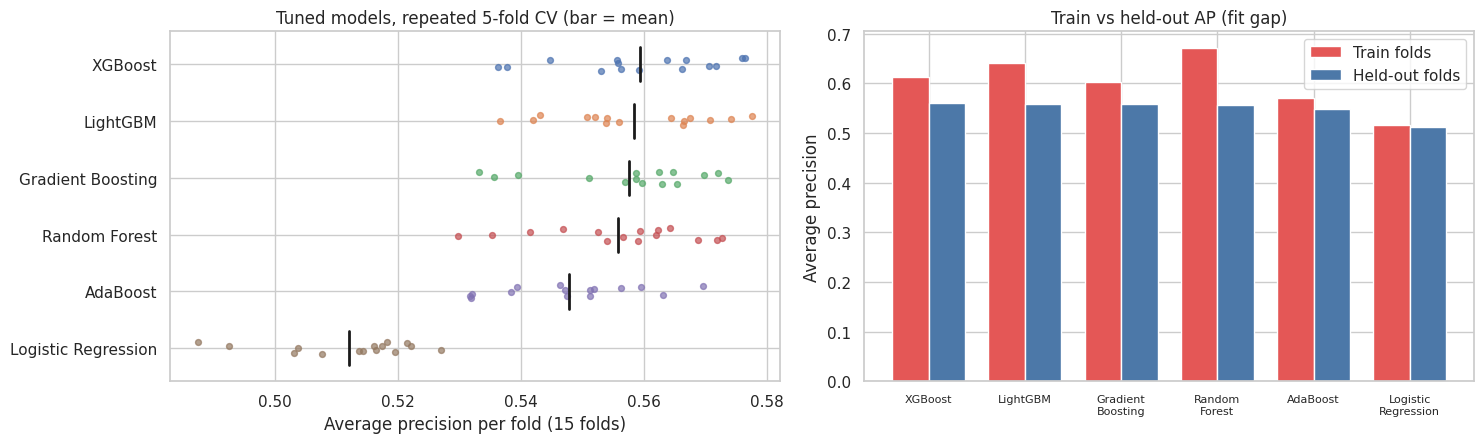

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
order = list(rank.index)
for i, n in enumerate(order):
    v = rep[n]['test_ap']; axes[0].scatter(v, np.full_like(v, i, dtype=float) + np.random.uniform(-0.12, 0.12, len(v)), s=18, alpha=0.7)
    axes[0].plot([v.mean()] * 2, [i - 0.3, i + 0.3], color='k', lw=2)
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order); axes[0].invert_yaxis(); axes[0].set_xlabel('Average precision per fold (15 folds)'); axes[0].set_title('Tuned models, repeated 5-fold CV (bar = mean)')
x = np.arange(len(order)); w = 0.38
axes[1].bar(x - w/2, rank['train AP'], w, label='Train folds', color='#E45756'); axes[1].bar(x + w/2, rank['AP mean'], w, label='Held-out folds', color='#4C78A8')
axes[1].set_xticks(x); axes[1].set_xticklabels([n.replace(' ', '\n') for n in order], fontsize=8); axes[1].set_ylabel('Average precision'); axes[1].set_title('Train vs held-out AP (fit gap)'); axes[1].legend()
plt.tight_layout(); plt.savefig('figures/fig_compare.png', dpi=130, bbox_inches='tight'); plt.show()

**Observations (15 paired folds).**
- **Four models are statistically tied at the top.** Mean AP: XGBoost 0.5593, LightGBM 0.5584, Gradient Boosting 0.5576, Random Forest 0.5558. Against XGBoost the corrected p-values are 0.69, 0.43 and 0.08, and every 95% interval for the difference includes zero. The four are within 0.0036 AP, so the data cannot say which is best.
- **AdaBoost (0.5478) and Logistic Regression (0.5120) are clearly lower** (corrected p = 0.003 and below 0.001 against XGBoost; differences of 0.012 and 0.047 AP).
- **Selection:** by the rule fixed in advance, the cheapest of the tied models is **XGBoost** (0.49 s per fold against 0.90 for LightGBM, 6.9 for Gradient Boosting and 10.1 for Random Forest). This is a tie-break on cost, not evidence that XGBoost is more accurate; LightGBM or Gradient Boosting would have been equally defensible.
- **Fit gaps (train − held-out AP):** XGBoost 0.053, LightGBM 0.082, Gradient Boosting 0.045, Random Forest 0.115, AdaBoost 0.023, Logistic Regression 0.004. Tuned XGBoost overfits less than its default (0.134).

## 8. Evaluation Metrics

### 8.1 Cost assumption and threshold, fixed on training data only

Out-of-fold (OOF) predictions on the training split are produced by the selected model with 5-fold CV: each customer is scored by a model that never saw them. The cost per customer of a rule that flags customers with score ≥ *t* is

`cost(t) = (5 × missed defaulters + 1 × false alarms) / number of customers`

(the 5 : 1 assumption from section 1). The threshold is the value minimising this cost on the OOF predictions. The same procedure is applied to the baseline (balanced Logistic Regression on raw columns) so both are compared fairly. A sensitivity table repeats the choice for other cost ratios.

,cost/customer,recall,flagged %,threshold,precision,F1,TP,FP,FN
Flag nobody,1.106,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN
Flag everybody,0.779,1.000,1.000,NaN,NaN,NaN,NaN,NaN,NaN
"Baseline LR (balanced), cost-optimal threshold",0.593,0.642,0.339,0.491,0.419,0.507,2723.0,3777.0,1518.0
"XGBoost, cost-optimal threshold",0.545,0.743,0.426,0.501,0.386,0.508,3153.0,5012.0,1088.0


,threshold,precision,recall,flagged %,cost final,cost baseline LR,saving vs baseline,cost flag-all / nobody (best)
cost ratio,,,,,,,,
2,0.669,0.548,0.546,0.220,0.301,0.321,0.064,0.442
3,0.611,0.498,0.609,0.270,0.395,0.424,0.069,0.663
5,0.501,0.386,0.743,0.426,0.545,0.593,0.080,0.779
8,0.369,0.298,0.895,0.663,0.651,0.729,0.107,0.779
10,0.318,0.275,0.934,0.750,0.690,0.757,0.088,0.779


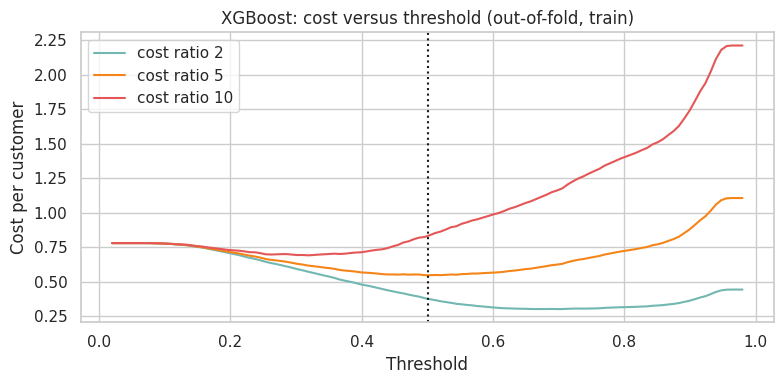

In [ ]:
COST_RATIO = 5
final_pipe = build(FINAL_NAME, TUNED[FINAL_NAME])
base_pipe = lr_pipeline(V0, class_weight='balanced')
def _oof():
    return {'final': cross_val_predict(final_pipe, X_train, y_train, cv=cv5, method='predict_proba', n_jobs=1)[:, 1],
            'base': cross_val_predict(base_pipe, X_train, y_train, cv=cv5, method='predict_proba', n_jobs=1)[:, 1]}
oof = cached('oof_' + FINAL_NAME.replace(' ', '_'), _oof)
yt = y_train.values
def counts(p, t, y_=yt):
    pred = p >= t; tp = int((pred & (y_ == 1)).sum()); fp = int((pred & (y_ == 0)).sum()); fn = int((~pred & (y_ == 1)).sum()); tn = int((~pred & (y_ == 0)).sum())
    return tp, fp, fn, tn
def cost(p, t, ratio, y_=yt):
    tp, fp, fn, tn = counts(p, t, y_); return (ratio * fn + fp) / len(y_)
def best_threshold(p, ratio):
    grid = np.unique(np.quantile(p, np.linspace(0.0, 1.0, 600)))
    costs = np.array([cost(p, t, ratio) for t in grid]); return float(grid[costs.argmin()]), float(costs.min())
def op_row(p, t, ratio=COST_RATIO, y_=yt):
    tp, fp, fn, tn = counts(p, t, y_); prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {'threshold': t, 'precision': prec, 'recall': rec, 'F1': 2 * prec * rec / max(prec + rec, 1e-12), 'flagged %': (tp + fp) / len(y_),
            'TP': tp, 'FP': fp, 'FN': fn, 'cost/customer': (ratio * fn + fp) / len(y_)}
thr_final, c_final = best_threshold(oof['final'], COST_RATIO); thr_base, c_base = best_threshold(oof['base'], COST_RATIO)
pos_rate = yt.mean(); no_flag_cost = COST_RATIO * pos_rate; flag_all_cost = 1 - pos_rate
table = pd.DataFrame({'Flag nobody': {'cost/customer': no_flag_cost, 'recall': 0.0, 'flagged %': 0.0}, 'Flag everybody': {'cost/customer': flag_all_cost, 'recall': 1.0, 'flagged %': 1.0},
                      'Baseline LR (balanced), cost-optimal threshold': op_row(oof['base'], thr_base), f'{FINAL_NAME}, cost-optimal threshold': op_row(oof['final'], thr_final)}).T
display(table.round(3))
RESULTS['cost'] = {'ratio': COST_RATIO, 'thr_final': thr_final, 'thr_base': thr_base, 'no_flag': no_flag_cost, 'flag_all': flag_all_cost,
                   'oof_final': op_row(oof['final'], thr_final), 'oof_base': op_row(oof['base'], thr_base)}
sens = []
for r_ in [2, 3, 5, 8, 10]:
    t_, c_ = best_threshold(oof['final'], r_); row = op_row(oof['final'], t_, r_); tb_, cb_ = best_threshold(oof['base'], r_)
    sens.append({'cost ratio': r_, 'threshold': t_, 'precision': row['precision'], 'recall': row['recall'], 'flagged %': row['flagged %'], 'cost final': c_, 'cost baseline LR': cb_,
                 'saving vs baseline': 1 - c_ / cb_, 'cost flag-all / nobody (best)': min(1 - pos_rate, r_ * pos_rate)})
sens = pd.DataFrame(sens).set_index('cost ratio'); display(sens.round(3)); RESULTS['sens'] = sens.round(4).reset_index().to_dict('records')
fig, ax = plt.subplots(figsize=(8, 4)); grid = np.linspace(0.02, 0.98, 120)
for r_, c_ in [(2, '#72B7B2'), (5, '#F58518'), (10, '#E45756')]:
    ax.plot(grid, [cost(oof['final'], t, r_) for t in grid], color=c_, label=f'cost ratio {r_}')
ax.axvline(thr_final, color='k', ls=':'); ax.set_xlabel('Threshold'); ax.set_ylabel('Cost per customer'); ax.set_title(f'{FINAL_NAME}: cost versus threshold (out-of-fold, train)'); ax.legend()
plt.tight_layout(); plt.savefig('figures/fig_cost.png', dpi=130, bbox_inches='tight'); plt.show()

**Observations (out-of-fold, training split; cost ratio 5 : 1).**
- **Trivial rules:** flagging nobody costs 1.106 per customer, flagging everybody 0.779. Flag-everybody is cheaper once the cost ratio exceeds about 3.5 (the ratio of non-defaulters to defaulters), so the model must beat 0.779 to add value at ratio 5.
- **XGBoost at its cost-optimal threshold (0.501)** costs 0.545 per customer: recall 0.74, precision 0.39, 43% of customers flagged (3,153 defaulters caught, 1,088 missed, 5,012 false alarms). That is 30% below the best trivial rule and 8% below the balanced Logistic Regression baseline (0.593), which at its own threshold catches 64% of defaulters and flags 34%.
- **The threshold is close to 0.5 partly by construction:** the tuned class weight of 5 equals the assumed cost ratio, which pushes scores upward. This is a plausible explanation, not something tested, and it also means scores are not calibrated probabilities (see 8.2).
- **Sensitivity to the cost ratio:** at ratio 2 the best threshold is 0.669 (recall 0.55, precision 0.55, 22% flagged); at ratio 3, 0.611 (recall 0.61); at ratio 8, 0.369 (recall 0.90, 66% flagged); at ratio 10, 0.318 (recall 0.93, 75% flagged). The model's cost advantage over the baseline stays between 6% and 11% across ratios, but at high ratios its advantage over simply flagging everyone narrows (ratio 10: 0.690 against 0.779). The choice of 5 changes how many customers are flagged much more than it changes which model is better.

### 8.2 Final evaluation on the held-out test split (used once)

The selected model is fitted on the **full training split**, the threshold fixed in 8.1 is applied unchanged, and the test split is scored once. The baseline (fitted on the training split, with its own training-chosen threshold) is scored the same way. Bootstrap confidence intervals (1,000 resamples of the test rows) show how much the test figures could vary by chance.

In [ ]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix, brier_score_loss)
Xte, yte = use_test(); ye = yte.values
final_fit = clone(final_pipe).fit(X_train, y_train); base_fit = clone(base_pipe).fit(X_train, y_train)
p_te = final_fit.predict_proba(Xte)[:, 1]; p_te_b = base_fit.predict_proba(Xte)[:, 1]
def test_row(p, t): r = op_row(p, t, COST_RATIO, ye); r.update({'AP': average_precision_score(ye, p), 'ROC-AUC': roc_auc_score(ye, p)}); return r
res_final, res_base = test_row(p_te, thr_final), test_row(p_te_b, thr_base)
test_table = pd.DataFrame({'Baseline LR (balanced)': res_base, FINAL_NAME: res_final}).T
test_table['cost nobody'] = COST_RATIO * ye.mean(); test_table['cost everybody'] = 1 - ye.mean()
display(test_table.round(3))
rng = np.random.default_rng(RANDOM_STATE); boots = []
for _ in range(1000):
    i = rng.integers(0, len(ye), len(ye))
    if ye[i].min() == ye[i].max(): continue
    boots.append((average_precision_score(ye[i], p_te[i]), roc_auc_score(ye[i], p_te[i]), op_row(p_te[i], thr_final, COST_RATIO, ye[i])['cost/customer'],
                  op_row(p_te[i], thr_final, COST_RATIO, ye[i])['recall'], op_row(p_te[i], thr_final, COST_RATIO, ye[i])['precision']))
boots = np.array(boots); ci = {k: np.percentile(boots[:, j], [2.5, 97.5]) for j, k in enumerate(['AP', 'AUC', 'cost', 'recall', 'precision'])}
for k, v in ci.items(): print(f'{k:10s} 95% bootstrap interval: [{v[0]:.3f}, {v[1]:.3f}]')
tp_, fp_, fn_, tn_ = counts(p_te, thr_final, ye)
RESULTS['test'] = {'final': res_final, 'base': res_base, 'ci': {k: [float(a), float(b)] for k, (a, b) in ci.items()}, 'cm': [tn_, fp_, fn_, tp_],
                   'cost_nobody': float(COST_RATIO * ye.mean()), 'cost_all': float(1 - ye.mean()), 'brier': float(brier_score_loss(ye, p_te)), 'n_pos': int(ye.sum())}
RESULTS['test']['final']['threshold'] = thr_final

,threshold,precision,recall,F1,flagged %,TP,FP,FN,cost/customer,AP,ROC-AUC,cost nobody,cost everybody
Baseline LR (balanced),0.491,0.434,0.650,0.521,0.331,689.0,898.0,371.0,0.574,0.515,0.761,1.105,0.779
XGBoost,0.501,0.388,0.748,0.511,0.426,793.0,1249.0,267.0,0.539,0.577,0.792,1.105,0.779


AP         95% bootstrap interval: [0.545, 0.608]
AUC        95% bootstrap interval: [0.777, 0.807]
cost       95% bootstrap interval: [0.505, 0.574]
recall     95% bootstrap interval: [0.722, 0.774]
precision  95% bootstrap interval: [0.368, 0.411]


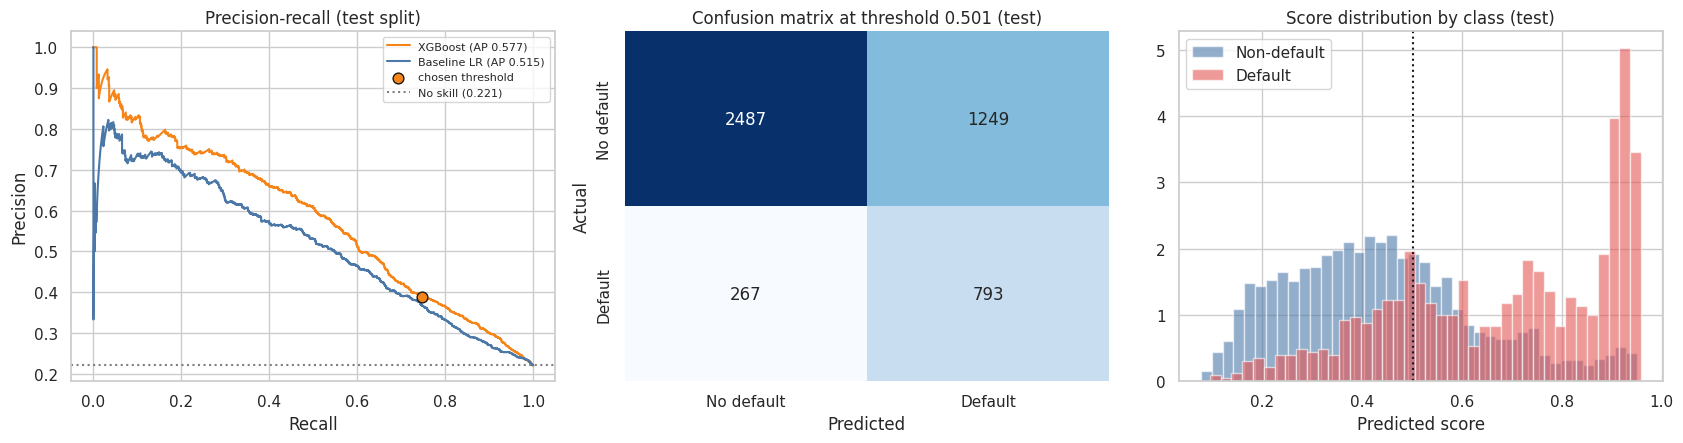

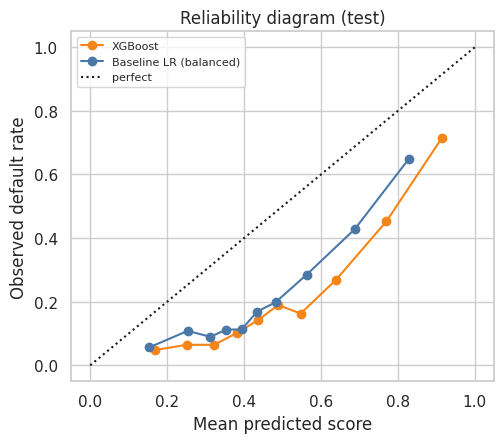

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
pr, rc, _ = precision_recall_curve(ye, p_te); prb, rcb, _ = precision_recall_curve(ye, p_te_b)
axes[0].plot(rc, pr, color='#F58518', label=f'{FINAL_NAME} (AP {res_final["AP"]:.3f})'); axes[0].plot(rcb, prb, color='#4C78A8', label=f'Baseline LR (AP {res_base["AP"]:.3f})')
axes[0].scatter([res_final['recall']], [res_final['precision']], color='#F58518', zorder=5, s=60, edgecolor='k', label='chosen threshold')
axes[0].axhline(ye.mean(), color='grey', ls=':', label=f'No skill ({ye.mean():.3f})'); axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision'); axes[0].set_title('Precision-recall (test split)'); axes[0].legend(fontsize=8)
sns.heatmap(confusion_matrix(ye, (p_te >= thr_final).astype(int)), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1], xticklabels=['No default', 'Default'], yticklabels=['No default', 'Default'])
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual'); axes[1].set_title(f'Confusion matrix at threshold {thr_final:.3f} (test)')
for lab, pp, c_ in [('Non-default', p_te[ye == 0], '#4C78A8'), ('Default', p_te[ye == 1], '#E45756')]: axes[2].hist(pp, bins=40, alpha=0.6, label=lab, color=c_, density=True)
axes[2].axvline(thr_final, color='k', ls=':'); axes[2].set_xlabel('Predicted score'); axes[2].set_title('Score distribution by class (test)'); axes[2].legend()
plt.tight_layout(); plt.savefig('figures/fig_test.png', dpi=130, bbox_inches='tight'); plt.show()

from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for lab, pp, c_ in [(FINAL_NAME, p_te, '#F58518'), ('Baseline LR (balanced)', p_te_b, '#4C78A8')]:
    fx, mx = calibration_curve(ye, pp, n_bins=10, strategy='quantile'); ax.plot(mx, fx, marker='o', label=lab, color=c_)
ax.plot([0, 1], [0, 1], 'k:', label='perfect'); ax.set_xlabel('Mean predicted score'); ax.set_ylabel('Observed default rate'); ax.set_title('Reliability diagram (test)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/fig_calibration.png', dpi=130, bbox_inches='tight'); plt.show()

**Test-split results (scored once; threshold 0.501 fixed on training data).**
- **Ranking:** XGBoost reaches AP 0.577 (95% bootstrap interval 0.545–0.608) and ROC-AUC 0.792 (0.777–0.807), against AP 0.515 and AUC 0.761 for the balanced Logistic Regression baseline (no-skill AP 0.221).
- **At the chosen threshold:** precision 0.388 (0.368–0.411), recall 0.748 (0.722–0.774), F1 0.511. It flags 42.6% of customers: 793 of 1,060 defaulters caught, 267 missed, 1,249 false alarms.
- **Cost:** 0.539 per customer (0.505–0.574), against 0.779 for flagging everybody, 1.105 for flagging nobody, and 0.574 for the baseline (recall 0.65, precision 0.43). The saving over the baseline is about 6% on the test split (8% out of fold); no paired test on the test split was run, so this modest difference should not be over-read.
- **Consistency:** test cost (0.539) matches out-of-fold cost (0.545), and test recall and precision match the out-of-fold values (0.743, 0.386), so the threshold carried over to unseen data.
- **Calibration:** both models' reliability curves lie below the diagonal: scores above 0.5 correspond to observed default rates well below the score, as expected from the class weight of 5. The scores rank customers and support a threshold, but they should not be read as probabilities of default without recalibration (not done here).

### 8.3 Interpretation: permutation importance and gain importance

**Permutation importance** is computed on the *held-out fold* of each of the 5 CV folds of the training split (3 shuffles each): the drop in AP when one original input column is shuffled. Because the engineered features are built from the raw columns inside the pipeline, shuffling a raw column removes its information from every feature derived from it. The test split is not used here. **Gain importance** (internal to tree models) is shown for the engineered features of the model fitted on the full training split.

,mean drop in AP,sd across folds
PAY_1,0.1951,0.0057
BILL_AMT1,0.0205,0.0038
PAY_2,0.0100,0.0052
LIMIT_BAL,0.0093,0.0046
BILL_AMT6,0.0068,0.0026
PAY_AMT3,0.0058,0.0025
PAY_3,0.0055,0.0039
PAY_AMT2,0.0041,0.0030
PAY_AMT1,0.0035,0.0042
EDUCATION,0.0032,0.0008


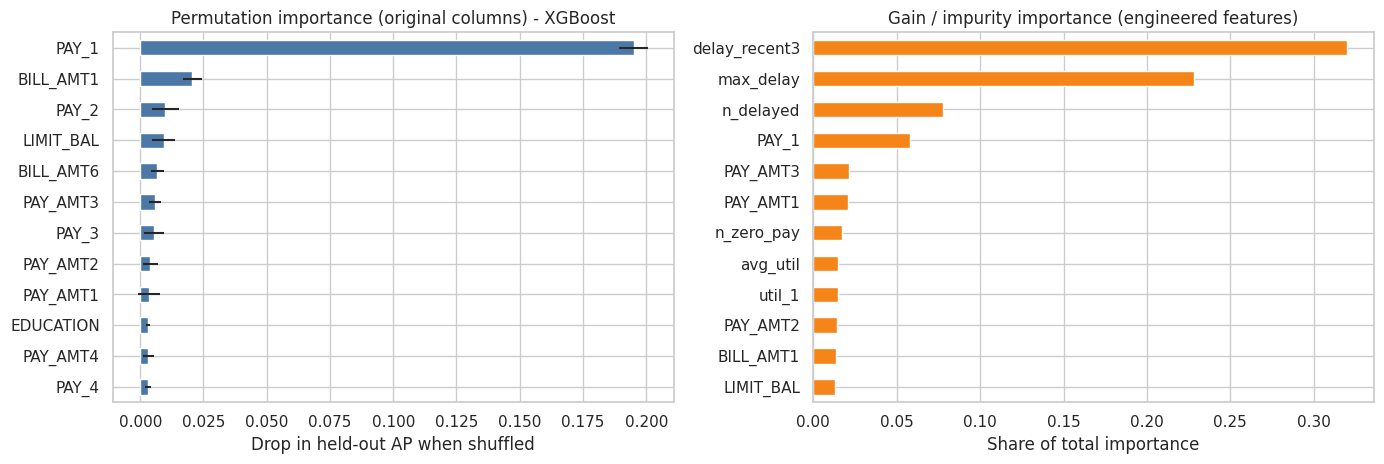

{'Repayment status (PAY_1-6)': 0.2179, 'Bill amounts (BILL_AMT1-6)': 0.0355, 'Payment amounts (PAY_AMT1-6)': 0.0208, 'Credit limit': 0.0093, 'Demographics (SEX, EDUCATION, MARRIAGE, AGE)': 0.0061}


In [ ]:
from sklearn.inspection import permutation_importance
def _perm():
    imps = []
    for tr, va in cv5.split(X_train, y_train):
        m = clone(final_pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring='average_precision', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
        imps.append(r.importances_mean)
    return np.array(imps)
perm = cached('perm_' + FINAL_NAME.replace(' ', '_'), _perm)
pi = pd.DataFrame({'mean drop in AP': perm.mean(axis=0), 'sd across folds': perm.std(axis=0)}, index=X_train.columns).sort_values('mean drop in AP', ascending=False)
group = {'Repayment status (PAY_1-6)': pay_cols, 'Bill amounts (BILL_AMT1-6)': bill_cols, 'Payment amounts (PAY_AMT1-6)': pay_amt_cols, 'Credit limit': ['LIMIT_BAL'], 'Demographics (SEX, EDUCATION, MARRIAGE, AGE)': ['SEX', 'EDUCATION', 'MARRIAGE', 'AGE']}
display(pi.head(12).round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pi.head(12).iloc[::-1]['mean drop in AP'].plot.barh(ax=axes[0], xerr=pi.head(12).iloc[::-1]['sd across folds'], color='#4C78A8'); axes[0].set_xlabel('Drop in held-out AP when shuffled'); axes[0].set_title(f'Permutation importance (original columns) - {FINAL_NAME}')
est = final_fit.named_steps['model']
if hasattr(est, 'feature_importances_'):
    fn_ = final_fit.named_steps['feat'].transform(X_train.head(2)).columns; gi = pd.Series(est.feature_importances_, index=fn_); gi = (gi / gi.sum()).sort_values(ascending=False)
    gi.head(12).iloc[::-1].plot.barh(ax=axes[1], color='#F58518'); axes[1].set_xlabel('Share of total importance'); axes[1].set_title('Gain / impurity importance (engineered features)'); RESULTS['gain_top'] = gi.head(10).round(4).to_dict()
plt.tight_layout(); plt.savefig('figures/fig_importance.png', dpi=130, bbox_inches='tight'); plt.show()
RESULTS['perm_top'] = pi.head(10).round(4).reset_index().rename(columns={'index': 'Column'}).to_dict('records')
RESULTS['perm_groups'] = {g_: float(pi.loc[cols, 'mean drop in AP'].sum()) for g_, cols in group.items()}
print({k: round(v, 4) for k, v in RESULTS['perm_groups'].items()})

**Observations.**
- **Repayment status dominates.** Shuffling `PAY_1` alone lowers held-out AP by 0.195, nearly ten times more than any other column (`BILL_AMT1` 0.021, `PAY_2` 0.010, `LIMIT_BAL` 0.009). By group, repayment status (PAY_1–6) accounts for a 0.218 drop, bills 0.036, payments 0.021, credit limit 0.009 and the four demographic fields 0.006. Group totals are sums of single-column drops and ignore interactions.
- **Gain importance agrees on the signal but shows the engineered summaries:** `delay_recent3` 32%, `max_delay` 23%, `n_delayed` 8% and `PAY_1` 6%, about 68% of total gain across the four delay features. Shuffling `BILL_AMT1` also matters partly because several engineered features (utilisation, payment ratios, bill trend) are built from it.
- **Demographics add little:** together they lower AP by only 0.006 when shuffled.
- Both measures show what the model uses, not what causes default.

### 8.4 Sensitive attributes: with versus without `SEX`, `AGE`, `MARRIAGE`

The selected model is re-evaluated with the three sensitive fields (and the age bin) removed inside the pipeline. Ranking quality is compared with the same repeated CV folds and the corrected paired test. Then both versions are compared on the **training-split OOF predictions** (each at its own cost-optimal threshold) by group: share of customers flagged, recall and precision. Finally the test-split breakdown of the final model is shown for reporting only; no decision uses it.

In [ ]:
fc_ns = {**FC, 'drop_sensitive': True}
pipe_ns = build(FINAL_NAME, TUNED[FINAL_NAME], fc=fc_ns)
rep_ns = cached('repcv_nosens', lambda: rep_eval(pipe_ns))
d_ap = rep[FINAL_NAME]['test_ap'] - rep_ns['test_ap']; m_, p_, lo_, hi_ = nb_test(d_ap)
print(f'With sensitive fields   : AP {rep[FINAL_NAME]["test_ap"].mean():.4f}, AUC {rep[FINAL_NAME]["test_auc"].mean():.4f}')
print(f'Without sensitive fields: AP {rep_ns["test_ap"].mean():.4f}, AUC {rep_ns["test_auc"].mean():.4f}')
print(f'Difference in AP (with - without): {m_:+.4f}, 95% CI [{lo_:+.4f}, {hi_:+.4f}], corrected p = {p_:.2f}')
RESULTS['sens_attr'] = {'with_ap': float(rep[FINAL_NAME]['test_ap'].mean()), 'without_ap': float(rep_ns['test_ap'].mean()), 'with_auc': float(rep[FINAL_NAME]['test_auc'].mean()),
                        'without_auc': float(rep_ns['test_auc'].mean()), 'diff': float(m_), 'p': float(p_), 'lo': float(lo_), 'hi': float(hi_)}
oof_ns = cached('oof_nosens_' + FINAL_NAME.replace(' ', '_'), lambda: cross_val_predict(pipe_ns, X_train, y_train, cv=cv5, method='predict_proba', n_jobs=1)[:, 1])
thr_ns, _ = best_threshold(oof_ns, COST_RATIO)
Fg = CreditFeatures(**FC, ).set_params(bins='both').fit(X_train).transform(X_train)
Fg_te = CreditFeatures(**FC).set_params(bins='both').fit(X_train).transform(Xte)
def group_table(p_with, t_with, p_without, t_without, F_, y_):
    rows = []
    for gname, ser, labels in [('SEX', X_ref['SEX'], {1: 'male', 2: 'female'}), ('Age band', F_['AGE_BIN'], dict(enumerate(age_labels))), ('MARRIAGE', F_['MARRIAGE'], {1: 'married', 2: 'single', 3: 'others'})]:
        for k, lab in labels.items():
            m = (ser == k).values; row = {'Group': gname, 'Level': lab, 'n': int(m.sum()), 'actual default': y_[m].mean()}
            for tag, p, t in [('with', p_with, t_with), ('without', p_without, t_without)]:
                if p is None: continue
                pr_ = (p[m] >= t); tp = (pr_ & (y_[m] == 1)).sum(); row[f'flagged ({tag})'] = pr_.mean(); row[f'recall ({tag})'] = tp / max((y_[m] == 1).sum(), 1); row[f'precision ({tag})'] = tp / max(pr_.sum(), 1)
            rows.append(row)
    return pd.DataFrame(rows)
X_ref = X_train
grp_oof = group_table(oof['final'], thr_final, oof_ns, thr_ns, Fg, yt); display(grp_oof.round(3))
X_ref = Xte
grp_te = group_table(p_te, thr_final, None, None, Fg_te, ye); display(grp_te.round(3))
RESULTS['grp_oof'] = grp_oof.round(4).to_dict('records'); RESULTS['grp_test'] = grp_te.round(4).to_dict('records')

With sensitive fields   : AP 0.5593, AUC 0.7857
Without sensitive fields: AP 0.5599, AUC 0.7855
Difference in AP (with - without): -0.0006, 95% CI [-0.0034, +0.0023], corrected p = 0.68


,Group,Level,n,actual default,flagged (with),recall (with),precision (with),flagged (without),recall (without),precision (without)
0,SEX,male,7671,0.242,0.467,0.763,0.395,0.455,0.748,0.399
1,SEX,female,11509,0.207,0.398,0.728,0.379,0.417,0.743,0.368
2,Age band,<25,1737,0.264,0.518,0.778,0.397,0.571,0.802,0.371
3,Age band,25-34,8268,0.205,0.389,0.712,0.376,0.411,0.728,0.364
4,Age band,35-49,7485,0.223,0.428,0.763,0.397,0.417,0.752,0.402
5,Age band,50-64,1617,0.245,0.506,0.763,0.369,0.466,0.727,0.382
6,Age band,65+,73,0.260,0.411,0.632,0.400,0.411,0.632,0.400
7,MARRIAGE,married,8751,0.236,0.456,0.767,0.397,0.430,0.746,0.409
8,MARRIAGE,single,10189,0.208,0.398,0.720,0.376,0.431,0.743,0.358
9,MARRIAGE,others,240,0.238,0.512,0.772,0.358,0.550,0.807,0.348


,Group,Level,n,actual default,flagged (with),recall (with),precision (with)
0,SEX,male,1898,0.245,0.465,0.789,0.416
1,SEX,female,2898,0.205,0.400,0.716,0.368
2,Age band,<25,423,0.274,0.546,0.819,0.411
3,Age band,25-34,2163,0.205,0.394,0.718,0.373
4,Age band,35-49,1794,0.213,0.416,0.738,0.378
5,Age band,50-64,403,0.285,0.511,0.817,0.456
6,Age band,65+,13,0.308,0.462,1.000,0.667
7,MARRIAGE,married,2136,0.230,0.449,0.772,0.395
8,MARRIAGE,single,2605,0.212,0.406,0.729,0.381
9,MARRIAGE,others,55,0.291,0.436,0.688,0.458


**Observations.**
- **Removing `SEX`, `AGE` and `MARRIAGE` costs nothing measurable:** AP 0.5593 with them, 0.5599 without (difference −0.0006, 95% interval −0.0034 to +0.0023, corrected p = 0.68), and AUC 0.7857 against 0.7855.
- **Out-of-fold group behaviour at each model's own cost-optimal threshold:** with the sensitive fields, men are flagged more than women (46.7% vs 39.8%, against actual default rates of 24.2% vs 20.7%) and recall differs by 3.5 points (0.763 vs 0.728). Without them, the flagging gap narrows (45.5% vs 41.7%) and the recall gap nearly closes (0.748 vs 0.743), but precision differs more (0.399 vs 0.368). By age band, customers under 25 are flagged at 51.8% with the fields and 57.1% without them (recall 0.778 and 0.802), so removing age does not reduce flagging of the youngest group; the cause was not investigated. The 65+ group (73 customers) and the "others" marital group (240) are too small to read.
- **Test split (final model, reporting only):** men are flagged at 46.5% with recall 0.789 and women at 40.0% with recall 0.716, a larger recall gap (7 points) than out of fold; the 65+ group has only 13 customers. These subgroup figures are noisy and no decision was based on them.
- **Reading:** the sensitive fields add no predictive value, so a deployment-minded choice would leave them out. The test evaluation above is of the model chosen by the pre-set rule, which includes them. This is a descriptive check, not a complete fairness assessment: other proxy variables remain, and the data have no information about outcomes for customers who were refused credit.

## 9. Generalization Discussion

Three views of generalization: (a) the gap between training-fold and held-out-fold scores, (b) a learning curve for the selected model, and (c) agreement between cross-validation, out-of-fold and test-split results.

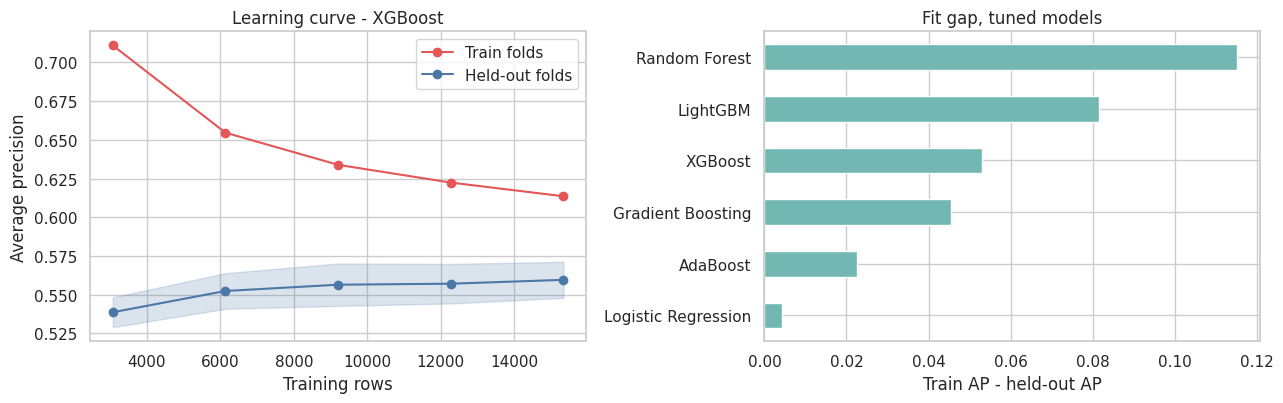

,Average precision,ROC-AUC
Repeated CV mean (train split),0.5593,0.7857
"Out-of-fold, pooled (train split)",0.5557,0.7852
Test split (held out),0.5766,0.7925


,train AP,held-out AP
3068,0.7110,0.5387
6137,0.6546,0.5524
9206,0.6339,0.5565
12275,0.6224,0.5571
15344,0.6136,0.5596


In [ ]:
from sklearn.model_selection import learning_curve
def _lc():
    sz, trs, vas = learning_curve(final_pipe, X_train, y_train, cv=cv5, train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], scoring='average_precision', n_jobs=1, shuffle=True, random_state=RANDOM_STATE)
    return {'sizes': sz, 'train': trs, 'val': vas}
lc = cached('learning_curve_' + FINAL_NAME.replace(' ', '_'), _lc)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(lc['sizes'], lc['train'].mean(axis=1), marker='o', label='Train folds', color='#E45756'); axes[0].plot(lc['sizes'], lc['val'].mean(axis=1), marker='o', label='Held-out folds', color='#4C78A8')
axes[0].fill_between(lc['sizes'], lc['val'].mean(axis=1) - lc['val'].std(axis=1), lc['val'].mean(axis=1) + lc['val'].std(axis=1), alpha=0.2, color='#4C78A8')
axes[0].set_xlabel('Training rows'); axes[0].set_ylabel('Average precision'); axes[0].set_title(f'Learning curve - {FINAL_NAME}'); axes[0].legend()
gap = pd.Series({n: rep[n]['train_ap'].mean() - rep[n]['test_ap'].mean() for n in rep}).sort_values(); gap.plot.barh(ax=axes[1], color='#72B7B2'); axes[1].set_xlabel('Train AP - held-out AP'); axes[1].set_title('Fit gap, tuned models')
plt.tight_layout(); plt.savefig('figures/fig_general.png', dpi=130, bbox_inches='tight'); plt.show()
agree = pd.DataFrame({'Average precision': [rep[FINAL_NAME]['test_ap'].mean(), average_precision_score(yt, oof['final']), res_final['AP']],
                      'ROC-AUC': [rep[FINAL_NAME]['test_auc'].mean(), roc_auc_score(yt, oof['final']), res_final['ROC-AUC']]},
                     index=['Repeated CV mean (train split)', 'Out-of-fold, pooled (train split)', 'Test split (held out)'])
display(agree.round(4)); display(pd.DataFrame({'train AP': lc['train'].mean(axis=1), 'held-out AP': lc['val'].mean(axis=1)}, index=lc['sizes']).round(4))
RESULTS['agree'] = agree.round(4).reset_index().rename(columns={'index': 'Source'}).to_dict('records')
RESULTS['lc'] = {'sizes': lc['sizes'].tolist(), 'train': lc['train'].mean(axis=1).round(4).tolist(), 'val': lc['val'].mean(axis=1).round(4).tolist()}
RESULTS['gap'] = gap.round(4).to_dict()

**Observations.**
- **Fit gaps:** the selected XGBoost model scores 0.61 on its training folds and 0.56 on held-out folds (gap 0.053), the second-smallest gap among the four top models and far below Random Forest (0.115) and untuned XGBoost (0.134). Moderate, not severe.
- **Learning curve:** held-out AP rises from 0.539 at 3,068 training rows to 0.552 at 6,137, 0.557 at 9,206 and 0.560 at 15,344, while train AP falls from 0.711 to 0.614 and the gap shrinks from 0.17 to 0.05. The held-out curve is nearly flat over the last 6,000 rows (+0.003), so more data of this kind is unlikely to help much; better features or different information would be needed for a larger gain.
- **Agreement across estimates:** repeated-CV AP 0.559, pooled out-of-fold AP 0.556 and test AP 0.577 (ROC-AUC 0.786, 0.785 and 0.792). The test score is slightly higher than the CV estimates (about 1.5 fold standard deviations) but inside the test bootstrap interval, which is consistent with sampling variation in 4,796 rows and gives no sign of the model being tuned to the training split.

## 10. Conclusion and Experiment Log

In [ ]:
log = pd.DataFrame([
    ['E1', 'Dummy / Logistic Regression baselines (raw columns)', f"AP {RESULTS['baseline']['Logistic Regression']['average_precision'][0]:.3f}", 'Section 5'],
    ['E2', 'Feature variants: raw, engineered, +bins, extended (LR and LightGBM, 15 folds)', f"selected: {RESULTS['fc']}", 'Section 3.4'],
    ['E3', 'Six models, default settings (5-fold)', 'see section 5 table', 'Section 5'],
    ['E4', 'Tuning: LR grid; LightGBM and XGBoost 30 trials; RF 10, GB 10, AdaBoost 8 trials', 'see section 6 table', 'Section 6'],
    ['E5', 'Imbalance handling on tuned LightGBM', 'see section 6.4 table', 'Section 6.4'],
    ['E6', 'Repeated CV (15 folds) with corrected paired tests; selection rule', f"selected: {RESULTS['final_name']}", 'Section 7'],
    ['E7', f'Cost assumption {COST_RATIO}:1, OOF threshold, sensitivity to ratio', f"threshold {RESULTS['cost']['thr_final']:.3f}", 'Section 8.1'],
    ['E8', 'Single test-split evaluation, bootstrap intervals, calibration', f"AP {RESULTS['test']['final']['AP']:.3f}, AUC {RESULTS['test']['final']['ROC-AUC']:.3f}", 'Section 8.2'],
    ['E9', 'Permutation importance; with/without sensitive attributes; subgroups', 'see sections 8.3-8.4', 'Sections 8.3-8.4'],
    ['E10', 'Learning curve and fit-gap analysis', 'see section 9', 'Section 9'],
], columns=['Experiment', 'What was done', 'Result / pointer', 'Where'])
display(log)
json.dump(RESULTS, open('outputs/week9_results.json', 'w'), indent=1, default=float); print('Saved outputs/week9_results.json')

,Experiment,What was done,Result / pointer,Where
0,E1,Dummy / Logistic Regression baselines (raw col...,AP 0.499,Section 5
1,E2,"Feature variants: raw, engineered, +bins, exte...","selected: {'engineered': 'True', 'bins': 'none'}",Section 3.4
2,E3,"Six models, default settings (5-fold)",see section 5 table,Section 5
3,E4,Tuning: LR grid; LightGBM and XGBoost 30 trial...,see section 6 table,Section 6
4,E5,Imbalance handling on tuned LightGBM,see section 6.4 table,Section 6.4
5,E6,Repeated CV (15 folds) with corrected paired t...,selected: XGBoost,Section 7
6,E7,"Cost assumption 5:1, OOF threshold, sensitivit...",threshold 0.501,Section 8.1
7,E8,"Single test-split evaluation, bootstrap interv...","AP 0.577, AUC 0.792",Section 8.2
8,E9,Permutation importance; with/without sensitive...,see sections 8.3-8.4,Sections 8.3-8.4
9,E10,Learning curve and fit-gap analysis,see section 9,Section 9


Saved outputs/week9_results.json


### Summary of findings

- **Problem and data:** predicting next-month default for credit card customers (P1), 23,976 rows after removing duplicates, 22.1% defaulters, split 80/20 with the test split used once.
- **What mattered most:** recent repayment behaviour. `PAY_1` alone accounts for most of the model's predictive value, and engineered delay summaries (`delay_recent3`, `max_delay`, `n_delayed`) carry about 68% of its gain importance. Credit limit adds a little; demographics, bill and payment amounts add little on top.
- **Feature engineering:** the engineered delay and utilisation features lifted Logistic Regression's AP from 0.499 to 0.512 and made little difference to trees. Binning and four additional features were tested and rejected.
- **Models:** the four tree ensembles (XGBoost, LightGBM, Gradient Boosting, Random Forest) are statistically tied (AP 0.556–0.559 over 15 folds); AdaBoost (0.548) and Logistic Regression (0.512) are clearly lower. Tuning gave small gains for the boosted trees and mainly reduced overfitting.
- **Final model:** tuned XGBoost (learning rate 0.020, depth 4, 277 trees, positive-class weight 5), chosen by the pre-set rule as the cheapest of the tied models, not because it is demonstrably better than LightGBM or Gradient Boosting.
- **Decision rule and test result:** with an assumed 5 : 1 cost of a missed defaulter versus a false alarm, the training-chosen threshold of 0.501 gave test AP 0.577, ROC-AUC 0.792, recall 0.75 and precision 0.39, flagging 43% of customers, at a cost 31% below flagging everybody (0.539 vs 0.779) and about 6% below the balanced Logistic Regression baseline (0.574).

### Limitations

- The cost ratio is an assumption; the data contain no loss or contact-cost figures. The best threshold and the number of customers flagged change strongly with it (section 8.1), and the model's advantage over flagging everyone narrows at high ratios.
- The differences between the top four models are not statistically distinguishable, and the test saving over the baseline was not tested for significance.
- The scores are not calibrated probabilities (the class weight shifts them upward); calibration was checked, not corrected.
- The Random Forest, Gradient Boosting and AdaBoost searches used 3-fold CV and only 8–10 trials; the best positive-class weight for the boosted trees sat at the upper edge of the range searched.
- The data are one snapshot (2005, Taiwan) with no customer ID, so there is no time-based or grouped split, and results may not transfer to other banks or periods. The working copy has 24,000 of the 30,000 UCI rows.
- The fairness analysis is limited to three recorded attributes and small groups at the extremes; it does not show that the model is fair.

### Recommendations and future work

- Choose the cost ratio from the bank's own loss and contact costs, and re-select the threshold on training data accordingly.
- Prefer the version without `SEX`, `AGE` and `MARRIAGE`, which performed the same in cross-validation, if the model were ever used.
- Recalibrate scores (for example with isotonic or Platt calibration on held-out data) if probabilities of default are needed.
- Repeat the comparison on the full 30,000-row UCI file and, if available, on data from a later period to check how well the results transfer.
- Search a wider range of positive-class weights and add features on the dynamics of repayment, since more rows of the same kind are unlikely to help much.

## References

1. Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H (CC BY 4.0). Working copy: https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/credit.csv
2. Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications*, 36(2), 2473–2480.
3. Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52, 239–281.
4. scikit-learn user guide and common pitfalls: https://scikit-learn.org/stable/common_pitfalls.html ; imbalanced-learn https://imbalanced-learn.org ; LightGBM https://lightgbm.readthedocs.io ; XGBoost https://xgboost.readthedocs.io
5. Course materials: *Binning: Turning Numbers into Groups* (Prasanna, 23 Oct 2026) and the *Target and Feature Lab*; Week-5 progress feedback.